# Semantic Similarity

In [1]:
analysis_deps = [
    "'apted>=1.0.3'",
    # "'matplotlib>=3.10.9'",
    "'rouge-score>=0.1.2'",
    "'sentence-transformers>=5.5.1'",
    "'nltk>=3.9.4'",
    "'prefixspan>=0.5.2'",
    "'scikit-learn>=1.8.0'",
    "'tol-colors>=2.2.0'",
    "'jupysql>=0.11.1'",
    "'duckdb>=1.5.1'",
]

In [2]:
!pip install {" ".join(analysis_deps)}

  Preparing metadata (setup.py) ... done
  Preparing metadata (setup.py) ... done
  Preparing metadata (setup.py) ... done
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.6/40.6 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 24.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 71.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 95.1/95.1 kB 6.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.5/21.5 MB 50.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 192.8/192.8 kB 9.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 396.1/396.1 kB 15.0 MB/s eta 0:00:00
  Created wheel for rouge-score: filename=rouge_score-0.1.2-py3-none-any.whl size=24934 sha256=9d5b49b3781c2c70d2426f7c6902463fe5b929fed2feff99478e0a3a74dc56dd
  Stored in directory: /root/.cache/pip/wheels/85/9d/af/01feefbe7d55ef5468796f0c68225b6788e85d9d0a281e7a70
  Created wheel for

In [3]:
!ls procedural_data || unzip -a procedural_data.zip

ls: cannot access 'procedural_data': No such file or directory
Archive:  procedural_data.zip
   creating: procedural_data/
  inflating: __MACOSX/._procedural_data  [binary]
  inflating: procedural_data/eml_author--cons_node_info_groups.csv  [binary]
  inflating: __MACOSX/procedural_data/._eml_author--cons_node_info_groups.csv  [binary]
  inflating: procedural_data/dwc-t_data--gt_node_info_groups.csv  [binary]
  inflating: __MACOSX/procedural_data/._dwc-t_data--gt_node_info_groups.csv  [binary]
  inflating: procedural_data/cons_gt_eml_author_nodes_cos_sim.csv  [binary]
  inflating: __MACOSX/procedural_data/._cons_gt_eml_author_nodes_cos_sim.csv  [binary]
  inflating: procedural_data/dwc-t_data--cons_node_info_groups.csv  [binary]
  inflating: __MACOSX/procedural_data/._dwc-t_data--cons_node_info_groups.csv  [binary]
  inflating: procedural_data/eml_author--gt_node_info_groups.csv  [binary]
  inflating: __MACOSX/procedural_data/._eml_author--gt_node_info_groups.csv  [binary]
  inflating:

In [4]:
import warnings

In [5]:
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

In [6]:
from duckdb.sqltypes import VARCHAR
import duckdb as ddb

In [7]:
from sklearn.metrics.pairwise import cosine_similarity
COS_SIMILARITY_READY = False
try:
    # NOTE: this can not run natively on Intel mac anymore
    from sentence_transformers import SentenceTransformer
    COS_SIMILARITY_READY = True
except ImportError as e:
    COS_SIMILARITY_READY = False
    warnings.warn("FAILED TO IMPORT `sentence_transformers`")
    warnings.warn(str(e))
finally:
    print(f"{COS_SIMILARITY_READY=}")

COS_SIMILARITY_READY=True


In [8]:
import tol_colors as tcls

In [9]:
import itertools as itlx
import json
from pathlib import Path
import re

In [10]:
from IPython.display import display, display_markdown

In [11]:
from pprint import pprint

In [12]:
tcls.set_default_colors()
plt.set_cmap(mpl.cm.tab20)

New config line: axes.prop_cycle : cycler('color', ['4477AA', 'EE6677', '228833', 'CCBB44', '66CCEE', 'AA3377', 'BBBBBB'])
Injecting line in file '/root/.config/matplotlib/matplotlibrc'


<Figure size 640x480 with 0 Axes>

## Data Loading

In [13]:
%config SqlMagic.autopandas = True
%load_ext sql
conn = ddb.connect()
%sql conn --alias duckdb

In [14]:
%%sql
CREATE TABLE IF NOT EXISTS cons_dwc_t_data_nodes AS
    SELECT * FROM './procedural_data/dwc-t_data--cons_node_info_groups.csv';

CREATE TABLE IF NOT EXISTS cons_dwc_t_author_nodes AS
    SELECT * FROM './procedural_data/dwc-t_author--cons_node_info_groups.csv';

CREATE TABLE IF NOT EXISTS cons_eml_data_nodes AS
    SELECT * FROM './procedural_data/eml_data--cons_node_info_groups.csv';

CREATE TABLE IF NOT EXISTS cons_eml_author_nodes AS
    SELECT * FROM './procedural_data/eml_author--cons_node_info_groups.csv';

Running query in 'duckdb'

,Count
0,5934


In [15]:
%%sql
CREATE TABLE IF NOT EXISTS gt_dwc_t_data_nodes AS
    SELECT * FROM './procedural_data/dwc-t_data--gt_node_info_groups.csv';

CREATE TABLE IF NOT EXISTS gt_dwc_t_author_nodes AS
    SELECT * FROM './procedural_data/dwc-t_author--gt_node_info_groups.csv';

CREATE TABLE IF NOT EXISTS gt_eml_data_nodes AS
    SELECT * FROM './procedural_data/eml_data--gt_node_info_groups.csv';

CREATE TABLE IF NOT EXISTS gt_eml_author_nodes AS
    SELECT * FROM './procedural_data/eml_author--gt_node_info_groups.csv';

Running query in 'duckdb'

,Count
0,53666


In [16]:
display(conn.query("DESCRIBE gt_dwc_t_data_nodes;"))
display(conn.query("DESCRIBE gt_dwc_t_author_nodes;"))
display(conn.query("DESCRIBE gt_eml_data_nodes;"))
display(conn.query("DESCRIBE gt_eml_author_nodes;"))

┌──────────────────┬─────────────┬─────────┬─────────┬─────────┬─────────┐
│   column_name    │ column_type │  null   │   key   │ default │  extra  │
│     varchar      │   varchar   │ varchar │ varchar │ varchar │ varchar │
├──────────────────┼─────────────┼─────────┼─────────┼─────────┼─────────┤
│ column00         │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ case_id          │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ tag              │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ depth            │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ degree           │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ is_leaf          │ BOOLEAN     │ YES     │ NULL    │ NULL    │ NULL    │
│ attributes       │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ attributes_count │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ has_attributes   │ BOOLEAN     │ YES     │ NULL    │ NULL    │ NULL    │
│ text             │ VARC

┌──────────────────┬─────────────┬─────────┬─────────┬─────────┬─────────┐
│   column_name    │ column_type │  null   │   key   │ default │  extra  │
│     varchar      │   varchar   │ varchar │ varchar │ varchar │ varchar │
├──────────────────┼─────────────┼─────────┼─────────┼─────────┼─────────┤
│ column00         │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ case_id          │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ tag              │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ depth            │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ degree           │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ is_leaf          │ BOOLEAN     │ YES     │ NULL    │ NULL    │ NULL    │
│ attributes       │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ attributes_count │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ has_attributes   │ BOOLEAN     │ YES     │ NULL    │ NULL    │ NULL    │
│ text             │ VARC

┌──────────────────┬─────────────┬─────────┬─────────┬─────────┬─────────┐
│   column_name    │ column_type │  null   │   key   │ default │  extra  │
│     varchar      │   varchar   │ varchar │ varchar │ varchar │ varchar │
├──────────────────┼─────────────┼─────────┼─────────┼─────────┼─────────┤
│ column00         │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ case_id          │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ tag              │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ depth            │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ degree           │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ is_leaf          │ BOOLEAN     │ YES     │ NULL    │ NULL    │ NULL    │
│ attributes       │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ attributes_count │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ has_attributes   │ BOOLEAN     │ YES     │ NULL    │ NULL    │ NULL    │
│ text             │ VARC

┌──────────────────┬─────────────┬─────────┬─────────┬─────────┬─────────┐
│   column_name    │ column_type │  null   │   key   │ default │  extra  │
│     varchar      │   varchar   │ varchar │ varchar │ varchar │ varchar │
├──────────────────┼─────────────┼─────────┼─────────┼─────────┼─────────┤
│ column00         │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ case_id          │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ tag              │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ depth            │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ degree           │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ is_leaf          │ BOOLEAN     │ YES     │ NULL    │ NULL    │ NULL    │
│ attributes       │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ attributes_count │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ has_attributes   │ BOOLEAN     │ YES     │ NULL    │ NULL    │ NULL    │
│ text             │ VARC

In [17]:
%%sql
SELECT COUNT(1) FROM cons_dwc_t_data_nodes;

Running query in 'duckdb'

,count(1)
0,8552


In [18]:
%%sql
SELECT COUNT(1) FROM cons_dwc_t_author_nodes;

Running query in 'duckdb'

,count(1)
0,8562


In [19]:
%%sql
SELECT COUNT(1) FROM cons_eml_data_nodes;

Running query in 'duckdb'

,count(1)
0,6369


In [20]:
%%sql
SELECT COUNT(1) FROM cons_eml_author_nodes;

Running query in 'duckdb'

,count(1)
0,5934


## By Shared Ancestor Paths

### Confusion Matrix

In [21]:
%%sql
CREATE TABLE IF NOT EXISTS shared_cons_gt_dwc_t_data_nodes AS (
    SELECT  *,
            c.text as cons_text, g.text as gt_text,
            c.has_text as cons_has_text, g.has_text as gt_has_text,
            c.attributes as cons_attributes, g.attributes as gt_attributes,
            c.has_attributes as cons_has_attributes, g.has_attributes as gt_has_attributes
    FROM cons_dwc_t_data_nodes AS c
    JOIN gt_dwc_t_data_nodes AS g
        ON  c.path = g.path
        AND c.case_id = g.case_id
);

Running query in 'duckdb'

,Count
0,8283


In [22]:
%sql SELECT COUNT(1) FROM shared_cons_gt_dwc_t_data_nodes;

Running query in 'duckdb'

,count(1)
0,8283


In [23]:
%%sql
CREATE TABLE IF NOT EXISTS shared_cons_gt_dwc_t_author_nodes AS (
    SELECT  *,
            c.text as cons_text, g.text as gt_text,
            c.has_text as cons_has_text, g.has_text as gt_has_text,
            c.attributes as cons_attributes, g.attributes as gt_attributes,
            c.has_attributes as cons_has_attributes, g.has_attributes as gt_has_attributes
    FROM cons_dwc_t_author_nodes AS c
    JOIN gt_dwc_t_author_nodes AS g
        ON  c.path = g.path
        AND c.case_id = g.case_id
);

Running query in 'duckdb'

,Count
0,8254


In [24]:
%%sql
CREATE TABLE IF NOT EXISTS shared_cons_gt_eml_data_nodes AS (
    SELECT  *,
            c.text as cons_text, g.text as gt_text,
            c.has_text as cons_has_text, g.has_text as gt_has_text,
            c.attributes as cons_attributes, g.attributes as gt_attributes,
            c.has_attributes as cons_has_attributes, g.has_attributes as gt_has_attributes
    FROM cons_eml_data_nodes AS c
    JOIN gt_eml_data_nodes AS g
        ON  c.path = g.path
        AND c.case_id = g.case_id
);

Running query in 'duckdb'

,Count
0,2844


In [25]:
%%sql
CREATE TABLE IF NOT EXISTS shared_cons_gt_eml_author_nodes AS (
    SELECT  *,
            c.text as cons_text, g.text as gt_text,
            c.has_text as cons_has_text, g.has_text as gt_has_text,
            c.attributes as cons_attributes, g.attributes as gt_attributes,
            c.has_attributes as cons_has_attributes, g.has_attributes as gt_has_attributes
    FROM cons_eml_author_nodes AS c
    JOIN gt_eml_author_nodes AS g
        ON  c.path = g.path
        AND c.case_id = g.case_id
);

Running query in 'duckdb'

,Count
0,2760


#### Reporting Confusion Matrix

In [26]:
# text

In [27]:
%%sql
SELECT COUNT(1), cons_has_text, gt_has_text
FROM shared_cons_gt_dwc_t_data_nodes
GROUP BY 2,3

Running query in 'duckdb'

,count(1),cons_has_text,gt_has_text
0,267,True,True
1,8016,False,False


In [28]:
%%sql
SELECT
    (SELECT COUNT(1) FROM shared_cons_gt_dwc_t_data_nodes WHERE cons_has_text AND cons_has_text)
    / (SELECT COUNT(1) FROM shared_cons_gt_dwc_t_data_nodes)
    * 100 AS tp_percentage;

Running query in 'duckdb'

,tp_percentage
0,3.22347


In [29]:
%%sql
SELECT COUNT(1), cons_has_text, gt_has_text
FROM shared_cons_gt_dwc_t_author_nodes
GROUP BY 2,3

Running query in 'duckdb'

,count(1),cons_has_text,gt_has_text
0,270,True,True
1,7984,False,False


In [30]:
%%sql
SELECT
    (SELECT COUNT(1) FROM shared_cons_gt_dwc_t_author_nodes WHERE cons_has_text AND cons_has_text)
    / (SELECT COUNT(1) FROM shared_cons_gt_dwc_t_author_nodes)
    * 100 AS tp_percentage;

Running query in 'duckdb'

,tp_percentage
0,3.271141


In [31]:
%%sql
SELECT COUNT(1), cons_has_text, gt_has_text
FROM shared_cons_gt_eml_data_nodes
GROUP BY 2,3

Running query in 'duckdb'

,count(1),cons_has_text,gt_has_text
0,864,True,True
1,1768,False,False
2,212,True,False


In [32]:
%%sql
SELECT
    (SELECT COUNT(1) FROM shared_cons_gt_eml_data_nodes WHERE cons_has_text AND cons_has_text)
    / (SELECT COUNT(1) FROM shared_cons_gt_eml_data_nodes)
    * 100 AS tp_percentage;

Running query in 'duckdb'

,tp_percentage
0,37.834037


In [33]:
%%sql
SELECT COUNT(1), cons_has_text, gt_has_text
FROM shared_cons_gt_eml_author_nodes
GROUP BY 2,3

Running query in 'duckdb'

,count(1),cons_has_text,gt_has_text
0,1704,False,False
1,219,True,False
2,834,True,True
3,3,False,True


In [34]:
%%sql
SELECT
    (SELECT COUNT(1) FROM shared_cons_gt_eml_author_nodes WHERE cons_has_text AND cons_has_text)
    / (SELECT COUNT(1) FROM shared_cons_gt_eml_author_nodes)
    * 100 AS tp_percentage;

Running query in 'duckdb'

,tp_percentage
0,38.152174


In [35]:
# attributes

In [36]:
%%sql
SELECT COUNT(1), cons_has_attributes, gt_has_attributes
FROM shared_cons_gt_dwc_t_data_nodes
GROUP BY 2,3

Running query in 'duckdb'

,count(1),cons_has_attributes,gt_has_attributes
0,7746,True,True
1,534,False,False
2,3,True,False


In [37]:
%%sql
SELECT
    (SELECT COUNT(1) FROM shared_cons_gt_dwc_t_data_nodes WHERE cons_has_attributes AND gt_has_attributes)
    / (SELECT COUNT(1) FROM shared_cons_gt_dwc_t_data_nodes)
    * 100 AS tp_percentage;

Running query in 'duckdb'

,tp_percentage
0,93.516842


In [38]:
%%sql
SELECT COUNT(1), cons_has_attributes, gt_has_attributes
FROM shared_cons_gt_dwc_t_author_nodes
GROUP BY 2,3

Running query in 'duckdb'

,count(1),cons_has_attributes,gt_has_attributes
0,540,False,False
1,3,True,False
2,7711,True,True


In [39]:
%%sql
SELECT
    (SELECT COUNT(1) FROM shared_cons_gt_dwc_t_author_nodes WHERE cons_has_attributes AND gt_has_attributes)
    / (SELECT COUNT(1) FROM shared_cons_gt_dwc_t_author_nodes)
    * 100 AS tp_percentage;

Running query in 'duckdb'

,tp_percentage
0,93.421371


In [40]:
%%sql
SELECT COUNT(1), cons_has_attributes, gt_has_attributes
FROM shared_cons_gt_eml_data_nodes
GROUP BY 2,3

Running query in 'duckdb'

,count(1),cons_has_attributes,gt_has_attributes
0,2451,False,False
1,15,True,False
2,180,True,True
3,198,False,True


In [41]:
%%sql
SELECT
    (SELECT COUNT(1) FROM shared_cons_gt_eml_data_nodes WHERE cons_has_attributes AND gt_has_attributes)
    / (SELECT COUNT(1) FROM shared_cons_gt_eml_data_nodes)
    * 100 AS tp_percentage;

Running query in 'duckdb'

,tp_percentage
0,6.329114


In [42]:
%%sql
SELECT COUNT(1), cons_has_attributes, gt_has_attributes
FROM shared_cons_gt_eml_author_nodes
GROUP BY 2,3

Running query in 'duckdb'

,count(1),cons_has_attributes,gt_has_attributes
0,2371,False,False
1,16,True,False
2,176,True,True
3,197,False,True


In [43]:
%%sql
SELECT
    (SELECT COUNT(1) FROM shared_cons_gt_eml_author_nodes WHERE cons_has_attributes AND gt_has_attributes)
    / (SELECT COUNT(1) FROM shared_cons_gt_eml_author_nodes)
    * 100 AS tp_percentage;

Running query in 'duckdb'

,tp_percentage
0,6.376812


### Computing Similarities

In [44]:
if COS_SIMILARITY_READY:
    sentence_transformer_model = SentenceTransformer('all-MiniLM-L6-v2')

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

tokenizer_config.json:   0%|          | 0.00/350 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

In [45]:
def compute_cos_similarity(v1: str, v2:str) -> float | None:
    if v1 == v2:
        return 1.0
    if not v1 or not v2:
        return None

    emb1 = sentence_transformer_model.encode(v1).reshape(1,-1)
    emb2 = sentence_transformer_model.encode(v2).reshape(1,-1)

    return cosine_similarity(emb1, emb2)[0][0].item()

In [46]:
compute_cos_similarity("{'index': '21', 'term': 'http://rs.tdwg.org/dwc/terms/kingdom'}", "{'index': '21', 'term': 'http://rs.tdwg.org/dwc/terms/kingdom'}")

1.0

In [47]:
conn.create_function("cos_sim", compute_cos_similarity)

In [48]:
# def wrap_text_struct(v: str) -> str:
#     return json.dumps({"text": v})

In [49]:
# ddb.create_function("wrap_text_struct", wrap_text_struct)

In [50]:
%%time
cons_gt_dwc_t_data_nodes_cos_sim_text = conn.query("""
SELECT
    case_id, path,
    cons_text, gt_text,
    cos_sim(cons_text, gt_text) AS cos_sim_text,
FROM shared_cons_gt_dwc_t_data_nodes
WHERE cons_has_text AND gt_has_text
""").to_df()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

CPU times: user 2.03 s, sys: 10.4 ms, total: 2.04 s
Wall time: 2.27 s


In [51]:
%%time
cons_gt_dwc_t_data_nodes_cos_sim_attributes = conn.query("""
SELECT
    case_id, path,
    cons_attributes, gt_attributes,
    cos_sim(cons_attributes, gt_attributes) AS cos_sim_attributes,
FROM shared_cons_gt_dwc_t_data_nodes
WHERE cons_has_attributes AND gt_has_attributes
""").to_df()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

CPU times: user 2min 40s, sys: 130 ms, total: 2min 40s
Wall time: 2min 42s


In [52]:
display(cons_gt_dwc_t_data_nodes_cos_sim_text.describe(include="all"))
display(cons_gt_dwc_t_data_nodes_cos_sim_attributes.describe(include="all"))

,case_id,path,cons_text,gt_text,cos_sim_text
count,267.000000,267,267,267,267.000000
unique,NaN,5,21,21,NaN
top,NaN,{http://rs.tdwg.org/dwc/text/}core/{http://rs....,occurrence.txt,occurrence.txt,NaN
freq,NaN,174,165,165,NaN
mean,87.707865,NaN,NaN,NaN,0.903594
std,52.224617,NaN,NaN,NaN,0.181778
min,0.000000,NaN,NaN,NaN,0.257896
25%,41.500000,NaN,NaN,NaN,1.000000
50%,86.000000,NaN,NaN,NaN,1.000000
75%,132.000000,NaN,NaN,NaN,1.000000


,case_id,path,cons_attributes,gt_attributes,cos_sim_attributes
count,7746.000000,7746,7746,7746,7746.000000
unique,NaN,322,2867,2807,NaN
top,NaN,{http://rs.tdwg.org/dwc/text/}core/{http://rs....,"{""index"": ""0""}","{""index"": ""0""}",NaN
freq,NaN,174,207,266,NaN
mean,88.934418,NaN,NaN,NaN,0.934057
std,51.635214,NaN,NaN,NaN,0.109447
min,0.000000,NaN,NaN,NaN,0.324183
25%,43.000000,NaN,NaN,NaN,0.867690
50%,91.000000,NaN,NaN,NaN,1.000000
75%,134.000000,NaN,NaN,NaN,1.000000


In [53]:
display(cons_gt_dwc_t_data_nodes_cos_sim_text)
display(cons_gt_dwc_t_data_nodes_cos_sim_attributes)

,case_id,path,cons_text,gt_text,cos_sim_text
0,0,{http://rs.tdwg.org/dwc/text/}core/{http://rs....,occurrence.txt,event.txt,0.64855
1,0,{http://rs.tdwg.org/dwc/text/}extension/{http:...,event.txt,occurrence.txt,0.64855
2,1,{http://rs.tdwg.org/dwc/text/}core/{http://rs....,occurrence.txt,occurrence.txt,1.00000
3,10,{http://rs.tdwg.org/dwc/text/}core/{http://rs....,occurrence.txt,occurrence.txt,1.00000
4,100,{http://rs.tdwg.org/dwc/text/}core/{http://rs....,occurrence.txt,occurrence.txt,1.00000
...,...,...,...,...,...
262,98,{http://rs.tdwg.org/dwc/text/}core/{http://rs....,event.txt,event.txt,1.00000
263,98,{http://rs.tdwg.org/dwc/text/}extension[1]/{ht...,occurrence.txt,occurrence.txt,1.00000
264,98,{http://rs.tdwg.org/dwc/text/}extension[2]/{ht...,extendedmeasurementorfact.txt,extendedmeasurementorfact.txt,1.00000
265,99,{http://rs.tdwg.org/dwc/text/}core/{http://rs....,event.txt,event.txt,1.00000


,case_id,path,cons_attributes,gt_attributes,cos_sim_attributes
0,0,.,"{""metadata"": ""meta.xml""}","{""metadata"": ""eml.xml""}",0.771236
1,0,{http://rs.tdwg.org/dwc/text/}core,"{""rowType"": ""http://rs.tdwg.org/dwc/terms/Occu...","{""encoding"": ""UTF-8"", ""fieldsTerminatedBy"": ""\...",0.888643
2,0,{http://rs.tdwg.org/dwc/text/}core/{http://rs....,"{""index"": ""0""}","{""index"": ""0""}",1.000000
3,0,{http://rs.tdwg.org/dwc/text/}core/{http://rs....,"{""index"": ""1"", ""term"": ""http://rs.tdwg.org/dwc...","{""index"": ""1"", ""term"": ""http://rs.tdwg.org/dwc...",0.862888
4,0,{http://rs.tdwg.org/dwc/text/}core/{http://rs....,"{""index"": ""2"", ""term"": ""http://rs.tdwg.org/dwc...","{""index"": ""2"", ""term"": ""http://rs.tdwg.org/dwc...",0.780676
...,...,...,...,...,...
7741,99,{http://rs.tdwg.org/dwc/text/}extension/{http:...,"{""index"": ""26"", ""term"": ""http://rs.tdwg.org/dw...","{""index"": ""26"", ""term"": ""http://rs.tdwg.org/dw...",1.000000
7742,99,{http://rs.tdwg.org/dwc/text/}extension/{http:...,"{""index"": ""27"", ""term"": ""http://rs.tdwg.org/dw...","{""index"": ""27"", ""term"": ""http://rs.tdwg.org/dw...",1.000000
7743,99,{http://rs.tdwg.org/dwc/text/}extension/{http:...,"{""index"": ""28"", ""term"": ""http://rs.tdwg.org/dw...","{""index"": ""28"", ""term"": ""http://rs.tdwg.org/dw...",1.000000
7744,99,{http://rs.tdwg.org/dwc/text/}extension/{http:...,"{""index"": ""29"", ""term"": ""http://rs.tdwg.org/dw...","{""index"": ""29"", ""term"": ""http://rs.tdwg.org/dw...",1.000000


<Axes: ylabel='Frequency'>

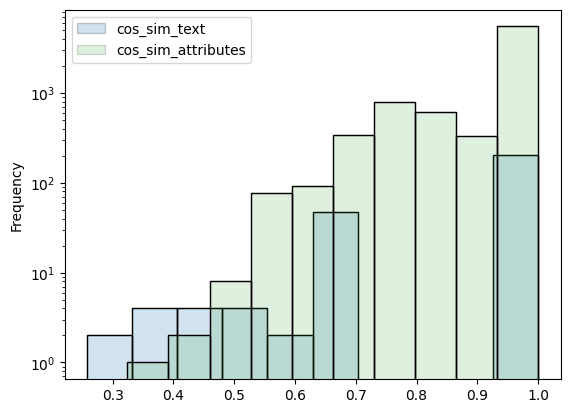

In [54]:
cons_gt_dwc_t_data_nodes_cos_sim_text["cos_sim_text"].plot.hist(alpha=0.2, ls="-", lw=1, edgecolor="k", legend=True, log=True)
cons_gt_dwc_t_data_nodes_cos_sim_text["cos_sim_text"].plot.hist(facecolor="#ffffff00", ls="--", lw=1, edgecolor="k")
cons_gt_dwc_t_data_nodes_cos_sim_attributes["cos_sim_attributes"].plot.hist(alpha=0.15, ls="-", lw=1, edgecolor="k", legend=True, log=True)
cons_gt_dwc_t_data_nodes_cos_sim_attributes["cos_sim_attributes"].plot.hist(facecolor="#ffffff00", ls="--", lw=1, edgecolor="k")

In [55]:
%%time
cons_gt_dwc_t_author_nodes_cos_sim_text = conn.query("""
SELECT
    case_id, path,
    cons_text, gt_text,
    cos_sim(cons_text, gt_text) AS cos_sim_text,
FROM shared_cons_gt_dwc_t_author_nodes
WHERE cons_has_text AND gt_has_text
""").to_df()

cons_gt_dwc_t_author_nodes_cos_sim_attributes = conn.query("""
SELECT
    case_id, path,
    cons_attributes, gt_attributes,
    cos_sim(cons_attributes, gt_attributes) AS cos_sim_attributes,
FROM shared_cons_gt_dwc_t_author_nodes
WHERE cons_has_attributes AND gt_has_attributes
""").to_df()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

CPU times: user 9min 23s, sys: 1min 1s, total: 10min 24s
Wall time: 7min 12s


In [56]:
%%time
cons_gt_eml_data_nodes_cos_sim_text = conn.query("""
SELECT
    case_id, path,
    cons_text, gt_text,
    cos_sim(cons_text, gt_text) AS cos_sim_text,
FROM shared_cons_gt_eml_data_nodes
WHERE cons_has_text AND gt_has_text
""").to_df()

cons_gt_eml_data_nodes_cos_sim_attributes = conn.query("""
SELECT
    case_id, path,
    cons_attributes, gt_attributes,
    cos_sim(cons_attributes, gt_attributes) AS cos_sim_attributes,
FROM shared_cons_gt_eml_data_nodes
WHERE cons_has_attributes AND gt_has_attributes
""").to_df()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

CPU times: user 1min 48s, sys: 3.99 s, total: 1min 52s
Wall time: 1min 28s


In [57]:
%%time
cons_gt_eml_author_nodes_cos_sim_text = conn.query("""
SELECT
    case_id, path,
    cons_text, gt_text,
    cos_sim(cons_text, gt_text) AS cos_sim_text,
FROM shared_cons_gt_eml_author_nodes
WHERE cons_has_text AND gt_has_text
""").to_df()

cons_gt_eml_author_nodes_cos_sim_attributes = conn.query("""
SELECT
    case_id, path,
    cons_attributes, gt_attributes,
    cos_sim(cons_attributes, gt_attributes) AS cos_sim_attributes,
FROM shared_cons_gt_eml_author_nodes
WHERE cons_has_attributes AND gt_has_attributes
""").to_df()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

CPU times: user 3min 24s, sys: 20.4 s, total: 3min 44s
Wall time: 2min 32s


#### Report Similarities

In [58]:
display(cons_gt_dwc_t_data_nodes_cos_sim_text.describe(include="all"))
display(cons_gt_dwc_t_data_nodes_cos_sim_attributes.describe(include="all"))

,case_id,path,cons_text,gt_text,cos_sim_text
count,267.000000,267,267,267,267.000000
unique,NaN,5,21,21,NaN
top,NaN,{http://rs.tdwg.org/dwc/text/}core/{http://rs....,occurrence.txt,occurrence.txt,NaN
freq,NaN,174,165,165,NaN
mean,87.707865,NaN,NaN,NaN,0.903594
std,52.224617,NaN,NaN,NaN,0.181778
min,0.000000,NaN,NaN,NaN,0.257896
25%,41.500000,NaN,NaN,NaN,1.000000
50%,86.000000,NaN,NaN,NaN,1.000000
75%,132.000000,NaN,NaN,NaN,1.000000


,case_id,path,cons_attributes,gt_attributes,cos_sim_attributes
count,7746.000000,7746,7746,7746,7746.000000
unique,NaN,322,2867,2807,NaN
top,NaN,{http://rs.tdwg.org/dwc/text/}core/{http://rs....,"{""index"": ""0""}","{""index"": ""0""}",NaN
freq,NaN,174,207,266,NaN
mean,88.934418,NaN,NaN,NaN,0.934057
std,51.635214,NaN,NaN,NaN,0.109447
min,0.000000,NaN,NaN,NaN,0.324183
25%,43.000000,NaN,NaN,NaN,0.867690
50%,91.000000,NaN,NaN,NaN,1.000000
75%,134.000000,NaN,NaN,NaN,1.000000


<Axes: ylabel='Frequency'>

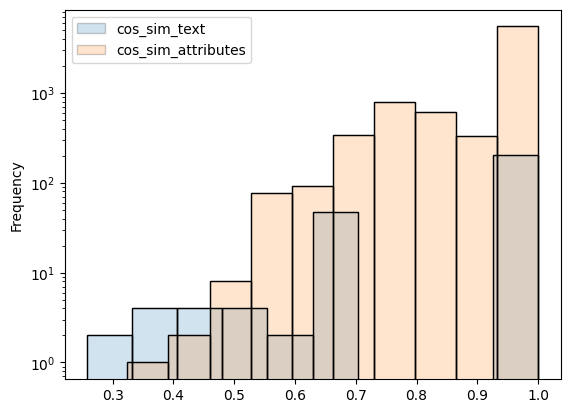

In [59]:
cons_gt_dwc_t_data_nodes_cos_sim_text["cos_sim_text"].plot.hist(alpha=0.2, ls="-", lw=1, edgecolor="k", legend=True, log=True)
cons_gt_dwc_t_data_nodes_cos_sim_attributes["cos_sim_attributes"].plot.hist(alpha=0.2, ls="-", lw=1, edgecolor="k", legend=True, log=True)
cons_gt_dwc_t_data_nodes_cos_sim_text["cos_sim_text"].plot.hist(facecolor="#ffffff00", ls="--", lw=1, edgecolor="k")
cons_gt_dwc_t_data_nodes_cos_sim_attributes["cos_sim_attributes"].plot.hist(facecolor="#ffffff00", ls="--", lw=1, edgecolor="k")

In [60]:
display(cons_gt_dwc_t_author_nodes_cos_sim_text.describe(include="all"))
display(cons_gt_dwc_t_author_nodes_cos_sim_attributes.describe(include="all"))

,case_id,path,cons_text,gt_text,cos_sim_text
count,270.000000,270,270,270,270.000000
unique,NaN,5,20,20,NaN
top,NaN,{http://rs.tdwg.org/dwc/text/}core/{http://rs....,occurrence.txt,occurrence.txt,NaN
freq,NaN,174,164,164,NaN
mean,88.029630,NaN,NaN,NaN,0.879655
std,51.026408,NaN,NaN,NaN,0.190179
min,0.000000,NaN,NaN,NaN,0.354693
25%,43.000000,NaN,NaN,NaN,0.648550
50%,86.500000,NaN,NaN,NaN,1.000000
75%,130.000000,NaN,NaN,NaN,1.000000


,case_id,path,cons_attributes,gt_attributes,cos_sim_attributes
count,7711.000000,7711,7711,7711,7711.000000
unique,NaN,320,2828,2761,NaN
top,NaN,{http://rs.tdwg.org/dwc/text/}core/{http://rs....,"{""index"": ""0""}","{""index"": ""0""}",NaN
freq,NaN,174,205,269,NaN
mean,89.425107,NaN,NaN,NaN,0.924877
std,50.600470,NaN,NaN,NaN,0.116797
min,0.000000,NaN,NaN,NaN,0.324183
25%,46.000000,NaN,NaN,NaN,0.838413
50%,91.000000,NaN,NaN,NaN,1.000000
75%,133.000000,NaN,NaN,NaN,1.000000


<Axes: ylabel='Frequency'>

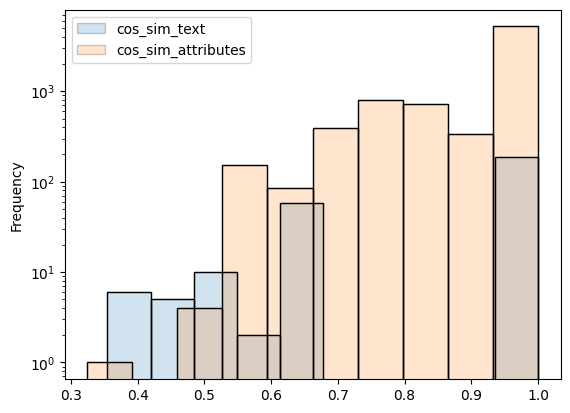

In [61]:
cons_gt_dwc_t_author_nodes_cos_sim_text["cos_sim_text"].plot.hist(alpha=0.2, ls="-", lw=1, edgecolor="k", legend=True, log=True)
cons_gt_dwc_t_author_nodes_cos_sim_attributes["cos_sim_attributes"].plot.hist(alpha=0.2, ls="-", lw=1, edgecolor="k", legend=True, log=True)
cons_gt_dwc_t_author_nodes_cos_sim_text["cos_sim_text"].plot.hist(facecolor="#ffffff00", ls="--", lw=1, edgecolor="k")
cons_gt_dwc_t_author_nodes_cos_sim_attributes["cos_sim_attributes"].plot.hist(facecolor="#ffffff00", ls="--", lw=1, edgecolor="k")

In [62]:
display(cons_gt_eml_data_nodes_cos_sim_text.describe(include="all"))
display(cons_gt_eml_data_nodes_cos_sim_attributes.describe(include="all"))

,case_id,path,cons_text,gt_text,cos_sim_text
count,864.000000,864,864,864,864.000000
unique,NaN,46,332,619,NaN
top,NaN,dataset/title,not-derived-011,unkown,NaN
freq,NaN,150,90,53,NaN
mean,83.092593,NaN,NaN,NaN,0.233270
std,52.995360,NaN,NaN,NaN,0.286662
min,0.000000,NaN,NaN,NaN,-0.132558
25%,39.000000,NaN,NaN,NaN,0.042006
50%,79.000000,NaN,NaN,NaN,0.115597
75%,130.000000,NaN,NaN,NaN,0.336362


,case_id,path,cons_attributes,gt_attributes,cos_sim_attributes
count,180.000000,180,180,180,180.000000
unique,NaN,5,73,154,NaN
top,NaN,.,"{""packageId"": ""not-derived-000"", ""system"": ""kn...","{""directory"": ""https://orcid.org/""}",NaN
freq,NaN,150,48,14,NaN
mean,87.516667,NaN,NaN,NaN,0.581811
std,52.733702,NaN,NaN,NaN,0.165776
min,0.000000,NaN,NaN,NaN,0.287758
25%,42.750000,NaN,NaN,NaN,0.449531
50%,86.500000,NaN,NaN,NaN,0.570834
75%,133.250000,NaN,NaN,NaN,0.594917


<Axes: ylabel='Frequency'>

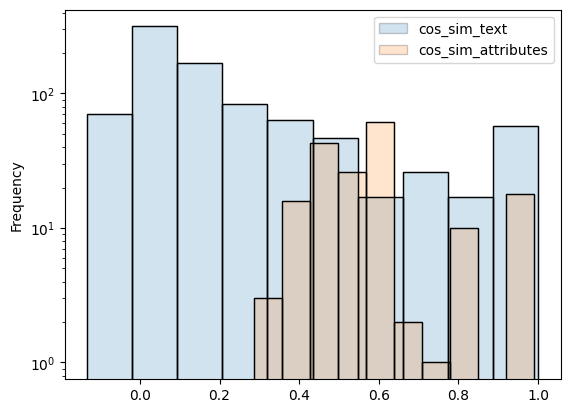

In [63]:
cons_gt_eml_data_nodes_cos_sim_text["cos_sim_text"].plot.hist(alpha=0.2, ls="-", lw=1, edgecolor="k", legend=True, log=True)
cons_gt_eml_data_nodes_cos_sim_attributes["cos_sim_attributes"].plot.hist(alpha=0.2, ls="-", lw=1, edgecolor="k", legend=True, log=True)
cons_gt_eml_data_nodes_cos_sim_text["cos_sim_text"].plot.hist(facecolor="#ffffff00", ls="--", lw=1, edgecolor="k")
cons_gt_eml_data_nodes_cos_sim_attributes["cos_sim_attributes"].plot.hist(facecolor="#ffffff00", ls="--", lw=1, edgecolor="k")

In [64]:
display(cons_gt_eml_author_nodes_cos_sim_text.describe(include="all"))
display(cons_gt_eml_author_nodes_cos_sim_attributes.describe(include="all"))

,case_id,path,cons_text,gt_text,cos_sim_text
count,834.000000,834,834,834,834.000000
unique,NaN,29,443,605,NaN
top,NaN,dataset/title,not-derived-011,unkown,NaN
freq,NaN,148,59,53,NaN
mean,88.726619,NaN,NaN,NaN,0.352775
std,51.816437,NaN,NaN,NaN,0.340538
min,0.000000,NaN,NaN,NaN,-0.099529
25%,46.250000,NaN,NaN,NaN,0.070197
50%,87.000000,NaN,NaN,NaN,0.230476
75%,137.750000,NaN,NaN,NaN,0.589701


,case_id,path,cons_attributes,gt_attributes,cos_sim_attributes
count,176.000000,176,176,176,176.000000
unique,NaN,3,76,152,NaN
top,NaN,.,"{""packageId"": ""not-derived-000"", ""system"": ""kn...","{""directory"": ""https://orcid.org/""}",NaN
freq,NaN,148,48,12,NaN
mean,91.784091,NaN,NaN,NaN,0.590347
std,50.980769,NaN,NaN,NaN,0.156639
min,0.000000,NaN,NaN,NaN,0.333798
25%,47.750000,NaN,NaN,NaN,0.494174
50%,91.500000,NaN,NaN,NaN,0.577721
75%,137.250000,NaN,NaN,NaN,0.607826


<Axes: ylabel='Frequency'>

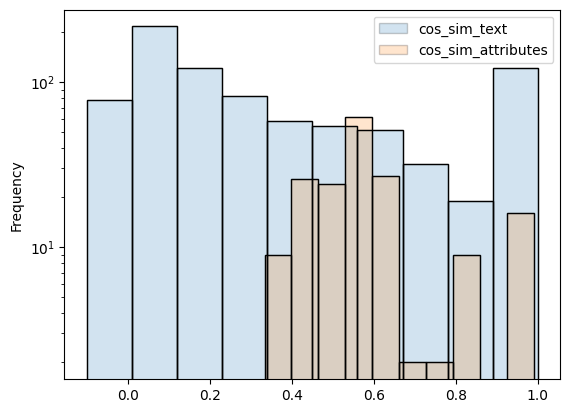

In [65]:
cons_gt_eml_author_nodes_cos_sim_text["cos_sim_text"].plot.hist(alpha=0.2, ls="-", lw=1, edgecolor="k", legend=True, log=True)
cons_gt_eml_author_nodes_cos_sim_attributes["cos_sim_attributes"].plot.hist(alpha=0.2, ls="-", lw=1, edgecolor="k", legend=True, log=True)
cons_gt_eml_author_nodes_cos_sim_text["cos_sim_text"].plot.hist(facecolor="#ffffff00", ls="--", lw=1, edgecolor="k")
cons_gt_eml_author_nodes_cos_sim_attributes["cos_sim_attributes"].plot.hist(facecolor="#ffffff00", ls="--", lw=1, edgecolor="k")

In [66]:
!mkdir -p output_data

In [67]:
cons_gt_dwc_t_data_nodes_cos_sim_text.to_csv("output_data/cons_gt_dwc_t_data_nodes_cos_sim_text.csv")
cons_gt_dwc_t_data_nodes_cos_sim_attributes.to_csv("output_data/cons_gt_dwc_t_data_nodes_cos_sim_attributes.csv")
cons_gt_dwc_t_author_nodes_cos_sim_text.to_csv("output_data/cons_gt_dwc_t_author_nodes_cos_sim_text.csv")
cons_gt_dwc_t_author_nodes_cos_sim_attributes.to_csv("output_data/cons_gt_dwc_t_author_nodes_cos_sim_attributes.csv")
cons_gt_eml_data_nodes_cos_sim_text.to_csv("output_data/cons_gt_eml_data_nodes_cos_sim_text.csv")
cons_gt_eml_data_nodes_cos_sim_attributes.to_csv("output_data/cons_gt_eml_data_nodes_cos_sim_attributes.csv")
cons_gt_eml_author_nodes_cos_sim_text.to_csv("output_data/cons_gt_eml_author_nodes_cos_sim_text.csv")
cons_gt_eml_author_nodes_cos_sim_attributes.to_csv("output_data/cons_gt_eml_author_nodes_cos_sim_attributes.csv")

In [68]:
!zip output_data.zip output_data/*

  adding: output_data/cons_gt_dwc_t_author_nodes_cos_sim_attributes.csv (deflated 93%)
  adding: output_data/cons_gt_dwc_t_author_nodes_cos_sim_text.csv (deflated 95%)
  adding: output_data/cons_gt_dwc_t_data_nodes_cos_sim_attributes.csv (deflated 93%)
  adding: output_data/cons_gt_dwc_t_data_nodes_cos_sim_text.csv (deflated 95%)
  adding: output_data/cons_gt_eml_author_nodes_cos_sim_attributes.csv (deflated 88%)
  adding: output_data/cons_gt_eml_author_nodes_cos_sim_text.csv (deflated 64%)
  adding: output_data/cons_gt_eml_data_nodes_cos_sim_attributes.csv (deflated 88%)
  adding: output_data/cons_gt_eml_data_nodes_cos_sim_text.csv (deflated 65%)


## Inspect results

In [69]:
conn.query("""
CREATE TABLE IF NOT EXISTS cons_gt_dwc_t_data_nodes_cos_sim_text AS
  SELECT * FROM cons_gt_dwc_t_data_nodes_cos_sim_text;

CREATE TABLE IF NOT EXISTS cons_gt_dwc_t_data_nodes_cos_sim_attributes AS
  SELECT * FROM cons_gt_dwc_t_data_nodes_cos_sim_attributes;

--

CREATE TABLE IF NOT EXISTS cons_gt_dwc_t_author_nodes_cos_sim_text AS
  SELECT * FROM cons_gt_dwc_t_author_nodes_cos_sim_text;

CREATE TABLE IF NOT EXISTS cons_gt_dwc_t_author_nodes_cos_sim_attributes AS
  SELECT * FROM cons_gt_dwc_t_author_nodes_cos_sim_attributes;

--

CREATE TABLE IF NOT EXISTS cons_gt_eml_data_nodes_cos_sim_text AS
  SELECT * FROM cons_gt_eml_data_nodes_cos_sim_text;

CREATE TABLE IF NOT EXISTS cons_gt_eml_data_nodes_cos_sim_attributes AS
  SELECT * FROM cons_gt_eml_data_nodes_cos_sim_attributes;

--

CREATE TABLE IF NOT EXISTS cons_gt_eml_author_nodes_cos_sim_text AS
  SELECT * FROM cons_gt_eml_author_nodes_cos_sim_text;

CREATE TABLE IF NOT EXISTS cons_gt_eml_author_nodes_cos_sim_attributes AS
  SELECT * FROM cons_gt_eml_author_nodes_cos_sim_attributes;
""")

### DwC-T

In [70]:
%%sql cons_gt_dwc_t_data_nodes_cos_sim_text__path_inspect <<
CREATE TABLE IF NOT EXISTS cons_gt_dwc_t_data_nodes_cos_sim_text__path_inspect AS (
  SELECT
    c.path,
    hash(c.path) AS hash_path,
    COUNT(case_id) as case_count,
    COUNT(cos_sim_text) as ds_count,
    stddev_pop(cos_sim_text) as ds_std_pop,
    AVG(cos_sim_text) as ds_mean,
    MAX(cos_sim_text) as ds_max,
    MIN(cos_sim_text) as ds_min,
    PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY cos_sim_text) AS ds_med_cont,
    PERCENTILE_CONT(0.25) WITHIN GROUP (ORDER BY cos_sim_text) AS ds_p25_cont,
    PERCENTILE_CONT(0.75) WITHIN GROUP (ORDER BY cos_sim_text) AS ds_p75_cont,
  FROM cons_gt_dwc_t_data_nodes_cos_sim_text as c
  GROUP BY c.path, hash_path
);
SELECT * FROM cons_gt_dwc_t_data_nodes_cos_sim_text__path_inspect;

Running query in 'duckdb'

In [71]:
%%sql cons_gt_dwc_t_data_nodes_cos_sim_attributes__path_inspect <<
CREATE TABLE IF NOT EXISTS cons_gt_dwc_t_data_nodes_cos_sim_attributes__path_inspect AS (
  SELECT
    c.path,
    hash(c.path) AS hash_path,
    COUNT(case_id) as case_count,
    COUNT(cos_sim_attributes) as ds_count,
    AVG(cos_sim_attributes) as ds_mean,
    stddev_pop(cos_sim_attributes) as ds_std_pop,
    MAX(cos_sim_attributes) as ds_max,
    MIN(cos_sim_attributes) as ds_min,
    PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY cos_sim_attributes) AS ds_med_cont,
    PERCENTILE_CONT(0.25) WITHIN GROUP (ORDER BY cos_sim_attributes) AS ds_p25_cont,
    PERCENTILE_CONT(0.75) WITHIN GROUP (ORDER BY cos_sim_attributes) AS ds_p75_cont,
  FROM cons_gt_dwc_t_data_nodes_cos_sim_attributes as c
  GROUP BY c.path, hash_path
);
SELECT * FROM cons_gt_dwc_t_data_nodes_cos_sim_attributes__path_inspect;

Running query in 'duckdb'

In [72]:
%%sql cons_gt_dwc_t_author_nodes_cos_sim_text__path_inspect <<
CREATE TABLE IF NOT EXISTS cons_gt_dwc_t_author_nodes_cos_sim_text__path_inspect AS (
  SELECT
    c.path,
    hash(c.path) AS hash_path,
    COUNT(case_id) as case_count,
    COUNT(cos_sim_text) as ds_count,
    stddev_pop(cos_sim_text) as ds_std_pop,
    AVG(cos_sim_text) as ds_mean,
    MAX(cos_sim_text) as ds_max,
    MIN(cos_sim_text) as ds_min,
    PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY cos_sim_text) AS ds_med_cont,
    PERCENTILE_CONT(0.25) WITHIN GROUP (ORDER BY cos_sim_text) AS ds_p25_cont,
    PERCENTILE_CONT(0.75) WITHIN GROUP (ORDER BY cos_sim_text) AS ds_p75_cont,
  FROM cons_gt_dwc_t_author_nodes_cos_sim_text as c
  GROUP BY c.path, hash_path
);
SELECT * FROM cons_gt_dwc_t_author_nodes_cos_sim_text__path_inspect;

Running query in 'duckdb'

In [73]:
%%sql cons_gt_dwc_t_author_nodes_cos_sim_attributes__path_inspect <<
CREATE TABLE IF NOT EXISTS cons_gt_dwc_t_author_nodes_cos_sim_attributes__path_inspect AS (
  SELECT
    c.path,
    hash(c.path) AS hash_path,
    COUNT(case_id) as case_count,
    COUNT(cos_sim_attributes) as ds_count,
    AVG(cos_sim_attributes) as ds_mean,
    stddev_pop(cos_sim_attributes) as ds_std_pop,
    MAX(cos_sim_attributes) as ds_max,
    MIN(cos_sim_attributes) as ds_min,
    PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY cos_sim_attributes) AS ds_med_cont,
    PERCENTILE_CONT(0.25) WITHIN GROUP (ORDER BY cos_sim_attributes) AS ds_p25_cont,
    PERCENTILE_CONT(0.75) WITHIN GROUP (ORDER BY cos_sim_attributes) AS ds_p75_cont,
  FROM cons_gt_dwc_t_author_nodes_cos_sim_attributes as c
  GROUP BY c.path, hash_path
);
SELECT * FROM cons_gt_dwc_t_author_nodes_cos_sim_attributes__path_inspect;

Running query in 'duckdb'

In [74]:
cons_gt_dwc_t_data_nodes_cos_sim_text__path_inspect = (
    cons_gt_dwc_t_data_nodes_cos_sim_text__path_inspect.sort_values(by="hash_path").set_index("hash_path")
)
cons_gt_dwc_t_data_nodes_cos_sim_attributes__path_inspect = (
    cons_gt_dwc_t_data_nodes_cos_sim_attributes__path_inspect.sort_values(by="hash_path").set_index("hash_path")
)
cons_gt_dwc_t_author_nodes_cos_sim_text__path_inspect = (
    cons_gt_dwc_t_author_nodes_cos_sim_text__path_inspect.sort_values(by="hash_path").set_index("hash_path")
)
cons_gt_dwc_t_author_nodes_cos_sim_attributes__path_inspect = (
    cons_gt_dwc_t_author_nodes_cos_sim_attributes__path_inspect.sort_values(by="hash_path").set_index("hash_path")
)

In [75]:
cons_gt_dwc_t_data_nodes_cos_sim_text__path_inspect

,path,case_count,ds_count,ds_std_pop,ds_mean,ds_max,ds_min,ds_med_cont,ds_p25_cont,ds_p75_cont
hash_path,,,,,,,,,,
2972828624038042123,{http://rs.tdwg.org/dwc/text/}extension[2]/{ht...,15,15,0.295611,0.735620,1.0,0.257896,1.000000,0.417432,1.000000
4300982297047325395,{http://rs.tdwg.org/dwc/text/}extension/{http:...,61,61,0.169136,0.882493,1.0,0.509599,1.000000,0.648550,1.000000
8026162855970452193,{http://rs.tdwg.org/dwc/text/}core/{http://rs....,174,174,0.125650,0.948706,1.0,0.509599,1.000000,1.000000,1.000000
11761823836042817577,{http://rs.tdwg.org/dwc/text/}extension[3]/{ht...,2,2,0.248102,0.751898,1.0,0.503796,0.751898,0.627847,0.875949
16898280223678874349,{http://rs.tdwg.org/dwc/text/}extension[1]/{ht...,15,15,0.268428,0.654307,1.0,0.257896,0.648550,0.417432,1.000000


In [76]:
cons_gt_dwc_t_author_nodes_cos_sim_text__path_inspect

,path,case_count,ds_count,ds_std_pop,ds_mean,ds_max,ds_min,ds_med_cont,ds_p25_cont,ds_p75_cont
hash_path,,,,,,,,,,
2972828624038042123,{http://rs.tdwg.org/dwc/text/}extension[2]/{ht...,16,16,0.252536,0.638249,1.00000,0.354693,0.512361,0.471848,1.000000
4300982297047325395,{http://rs.tdwg.org/dwc/text/}extension/{http:...,62,62,0.175980,0.856045,1.00000,0.509599,1.000000,0.648550,1.000000
8026162855970452193,{http://rs.tdwg.org/dwc/text/}core/{http://rs....,174,174,0.138226,0.934567,1.00000,0.509599,1.000000,1.000000,1.000000
11761823836042817577,{http://rs.tdwg.org/dwc/text/}extension[3]/{ht...,2,2,0.040978,0.607572,0.64855,0.566593,0.607572,0.587082,0.628061
16898280223678874349,{http://rs.tdwg.org/dwc/text/}extension[1]/{ht...,16,16,0.246570,0.649384,1.00000,0.354693,0.520925,0.497911,1.000000


In [77]:
set(cons_gt_dwc_t_data_nodes_cos_sim_text__path_inspect["path"].unique()) == set(cons_gt_dwc_t_author_nodes_cos_sim_text__path_inspect["path"].unique())

True

In [78]:
set(cons_gt_dwc_t_data_nodes_cos_sim_attributes__path_inspect["path"].unique()) == set(cons_gt_dwc_t_author_nodes_cos_sim_attributes__path_inspect["path"].unique())

False

In [79]:
print(f"{cons_gt_dwc_t_data_nodes_cos_sim_text__path_inspect.shape=}")
print(f"{cons_gt_dwc_t_data_nodes_cos_sim_attributes__path_inspect.shape=}")

print(f"{cons_gt_dwc_t_author_nodes_cos_sim_text__path_inspect.shape=}")
print(f"{cons_gt_dwc_t_author_nodes_cos_sim_attributes__path_inspect.shape=}")


cons_gt_dwc_t_data_nodes_cos_sim_text__path_inspect.shape=(5, 10)
cons_gt_dwc_t_data_nodes_cos_sim_attributes__path_inspect.shape=(322, 10)
cons_gt_dwc_t_author_nodes_cos_sim_text__path_inspect.shape=(5, 10)
cons_gt_dwc_t_author_nodes_cos_sim_attributes__path_inspect.shape=(320, 10)


#### Inspections DwC-T

In [80]:
# dwc-t + data

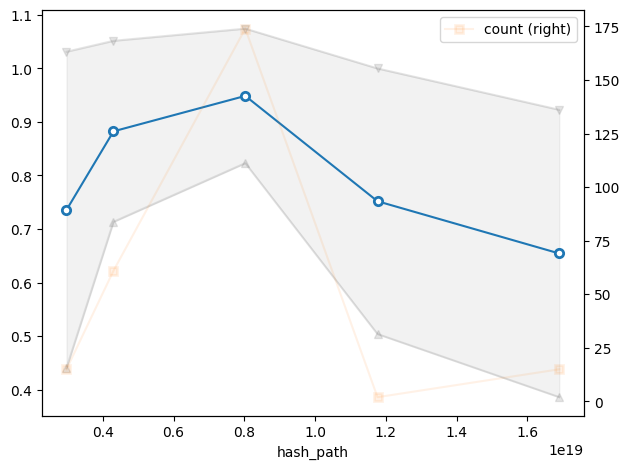

In [81]:
df = cons_gt_dwc_t_data_nodes_cos_sim_text__path_inspect
mean_plus_std = (df['ds_mean'] + df['ds_std_pop'])
mean_min_std = (df['ds_mean'] - df['ds_std_pop'])

plt.fill_between(df.index, mean_min_std, mean_plus_std, color="gray", alpha=0.1)
mean_plus_std.plot(alpha=0.2, marker="v", color="gray")
mean_min_std.plot(alpha=0.2, marker="^", color="gray")
df['ds_mean'].plot(marker="o", markerfacecolor="w", mew=2)
df['ds_count'].plot(alpha=0.1, marker="s", mew=2, secondary_y=True, label="count", legend=True)


plt.tight_layout()

<Axes: xlabel='hash_path'>

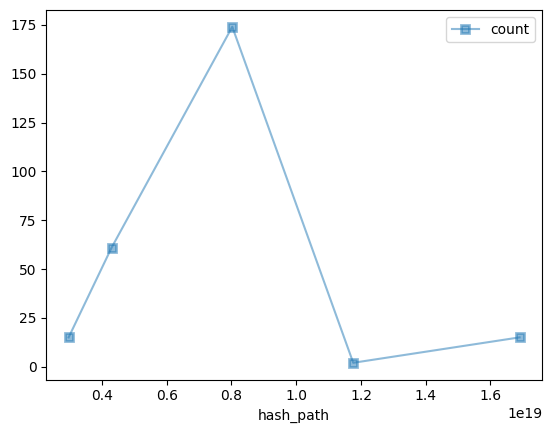

In [82]:
df = cons_gt_dwc_t_data_nodes_cos_sim_text__path_inspect
df['ds_count'].plot(alpha=0.5, marker="s", mew=2, label="count", legend=True)

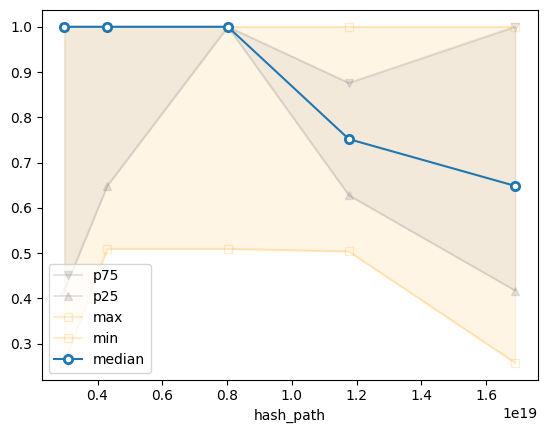

In [83]:
df = cons_gt_dwc_t_data_nodes_cos_sim_text__path_inspect
plt.fill_between(df.index, df["ds_max"], df["ds_min"], color="orange", alpha=0.1)
plt.fill_between(df.index, df["ds_p75_cont"], df["ds_p25_cont"], color="gray", alpha=0.1)
df["ds_p75_cont"].plot(alpha=0.2, marker="v", color="gray", label="p75", legend=True)
df["ds_p25_cont"].plot(alpha=0.2, marker="^", color="gray", label="p25", legend=True)
df['ds_min'].plot(alpha=0.2, marker="s", markerfacecolor="w", color="orange", label="max", legend=True)
df['ds_max'].plot(alpha=0.2, marker="s", markerfacecolor="w", color="orange", label="min", legend=True)
df['ds_med_cont'].plot(marker="o", markerfacecolor="w", mew=2, label="median", legend=True)
plt.legend(loc="lower left")
plt.show()

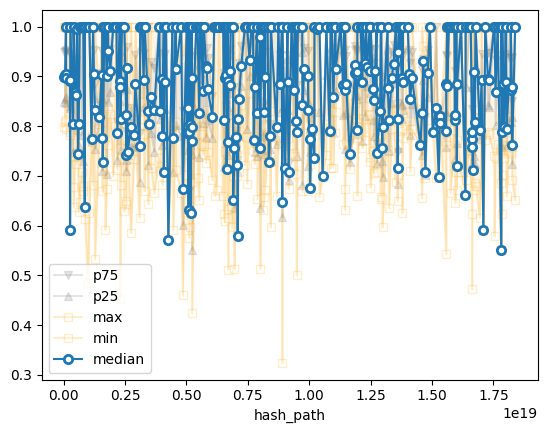

In [84]:
df = cons_gt_dwc_t_data_nodes_cos_sim_attributes__path_inspect
plt.fill_between(df.index, df["ds_max"], df["ds_min"], color="orange", alpha=0.1)
plt.fill_between(df.index, df["ds_p75_cont"], df["ds_p25_cont"], color="gray", alpha=0.1)
df["ds_p75_cont"].plot(alpha=0.2, marker="v", color="gray", label="p75", legend=True)
df["ds_p25_cont"].plot(alpha=0.2, marker="^", color="gray", label="p25", legend=True)
df['ds_min'].plot(alpha=0.2, marker="s", markerfacecolor="w", color="orange", label="max", legend=True)
df['ds_max'].plot(alpha=0.2, marker="s", markerfacecolor="w", color="orange", label="min", legend=True)
df['ds_med_cont'].plot(marker="o", markerfacecolor="w", mew=2, label="median", legend=True)
plt.legend(loc="lower left")
plt.show()

In [85]:
# dwc-t + author

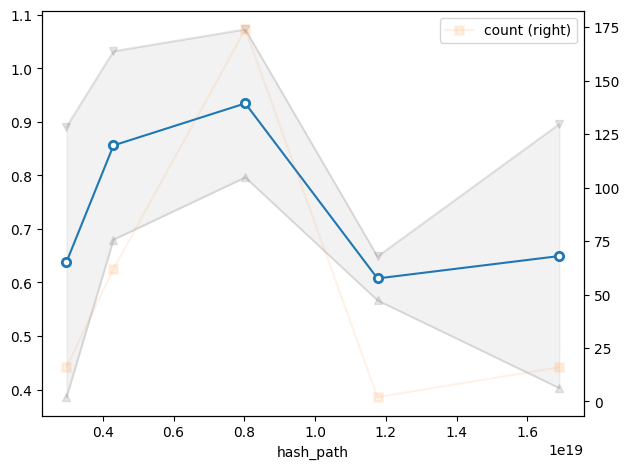

In [86]:
df = cons_gt_dwc_t_author_nodes_cos_sim_text__path_inspect
mean_plus_std = (df['ds_mean'] + df['ds_std_pop'])
mean_min_std = (df['ds_mean'] - df['ds_std_pop'])

plt.fill_between(df.index, mean_min_std, mean_plus_std, color="gray", alpha=0.1)
mean_plus_std.plot(alpha=0.2, marker="v", color="gray")
mean_min_std.plot(alpha=0.2, marker="^", color="gray")
df['ds_mean'].plot(marker="o", markerfacecolor="w", mew=2)
df['ds_count'].plot(alpha=0.1, marker="s", mew=2, secondary_y=True, label="count", legend=True)


plt.tight_layout()

<Axes: xlabel='hash_path'>

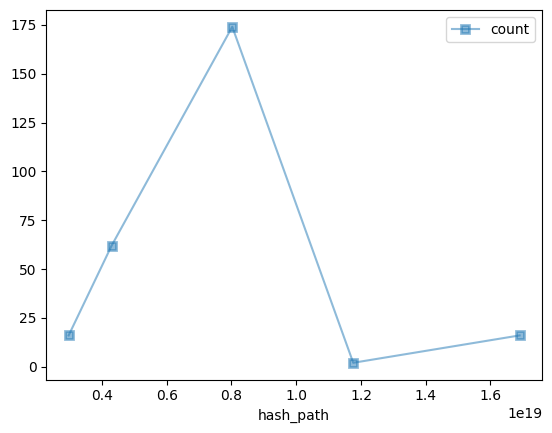

In [87]:
df = cons_gt_dwc_t_author_nodes_cos_sim_text__path_inspect
df['ds_count'].plot(alpha=0.5, marker="s", mew=2, label="count", legend=True)

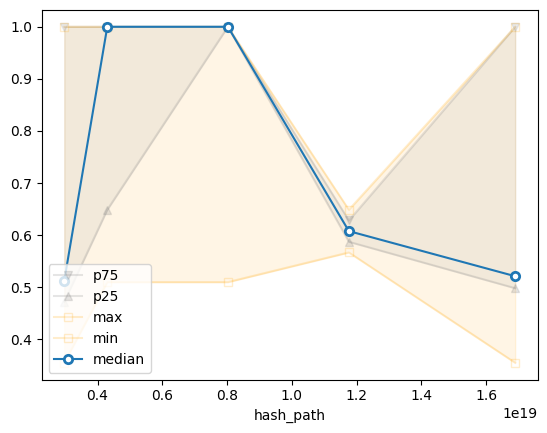

In [88]:
df = cons_gt_dwc_t_author_nodes_cos_sim_text__path_inspect
plt.fill_between(df.index, df["ds_max"], df["ds_min"], color="orange", alpha=0.1)
plt.fill_between(df.index, df["ds_p75_cont"], df["ds_p25_cont"], color="gray", alpha=0.1)
df["ds_p75_cont"].plot(alpha=0.2, marker="v", color="gray", label="p75", legend=True)
df["ds_p25_cont"].plot(alpha=0.2, marker="^", color="gray", label="p25", legend=True)
df['ds_min'].plot(alpha=0.2, marker="s", markerfacecolor="w", color="orange", label="max", legend=True)
df['ds_max'].plot(alpha=0.2, marker="s", markerfacecolor="w", color="orange", label="min", legend=True)
df['ds_med_cont'].plot(marker="o", markerfacecolor="w", mew=2, label="median", legend=True)
plt.legend(loc="lower left")
plt.show()

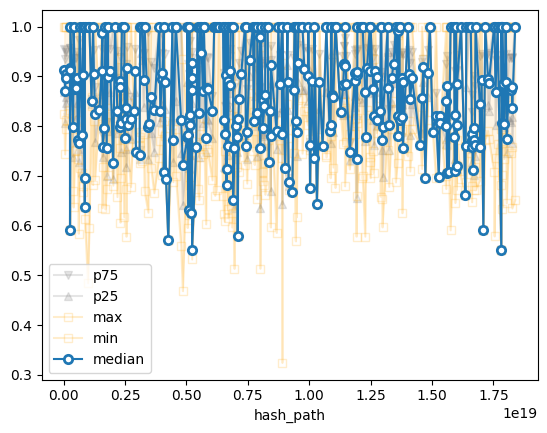

In [89]:
df = cons_gt_dwc_t_author_nodes_cos_sim_attributes__path_inspect
plt.fill_between(df.index, df["ds_max"], df["ds_min"], color="orange", alpha=0.1)
plt.fill_between(df.index, df["ds_p75_cont"], df["ds_p25_cont"], color="gray", alpha=0.1)
df["ds_p75_cont"].plot(alpha=0.2, marker="v", color="gray", label="p75", legend=True)
df["ds_p25_cont"].plot(alpha=0.2, marker="^", color="gray", label="p25", legend=True)
df['ds_min'].plot(alpha=0.2, marker="s", markerfacecolor="w", color="orange", label="max", legend=True)
df['ds_max'].plot(alpha=0.2, marker="s", markerfacecolor="w", color="orange", label="min", legend=True)
df['ds_med_cont'].plot(marker="o", markerfacecolor="w", mew=2, label="median", legend=True)
plt.legend(loc="lower left")
plt.show()

#### Compare DwC-T Data vs Author


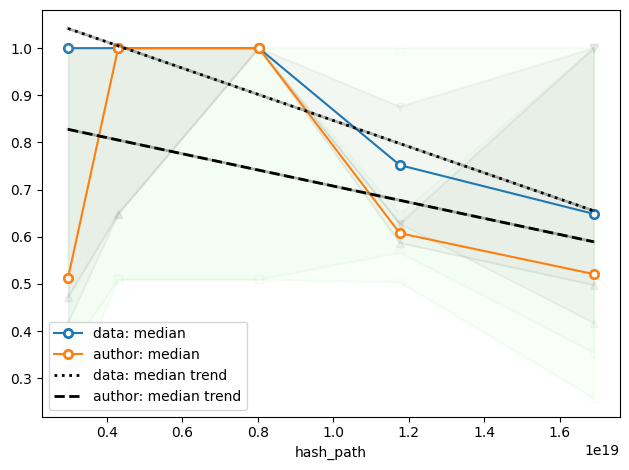

In [90]:
df1 = cons_gt_dwc_t_data_nodes_cos_sim_text__path_inspect
df2 = cons_gt_dwc_t_author_nodes_cos_sim_text__path_inspect

# data
plt.fill_between(df1.index, df1["ds_max"], df1["ds_min"], color="lightgreen", alpha=0.05)
plt.fill_between(df1.index, df1["ds_p75_cont"], df1["ds_p25_cont"], color="gray", alpha=0.05)
df1["ds_p75_cont"].plot(alpha=0.05, marker="v", color="gray", label="", legend=True)
df1["ds_p25_cont"].plot(alpha=0.05, marker="^", color="gray", label="", legend=True)
df1['ds_min'].plot(alpha=0.05, marker="s", markerfacecolor="w", color="lightgreen", label="", legend=True)
df1['ds_max'].plot(alpha=0.05, marker="s", markerfacecolor="w", color="lightgreen", label="", legend=True)
df1['ds_med_cont'].plot(marker="o", markerfacecolor="w", mew=2, label="data: median", legend=True)

# author
plt.fill_between(df2.index, df2["ds_max"], df2["ds_min"], color="lightgreen", alpha=0.05)
plt.fill_between(df2.index, df2["ds_p75_cont"], df2["ds_p25_cont"], color="gray", alpha=0.05)
df2["ds_p75_cont"].plot(alpha=0.1, marker="v", color="gray", label="", legend=True)
df2["ds_p25_cont"].plot(alpha=0.1, marker="^", color="gray", label="", legend=True)
df2['ds_min'].plot(alpha=0.05, marker="s", markerfacecolor="w", color="lightgreen", label="", legend=True)
df2['ds_max'].plot(alpha=0.05, marker="s", markerfacecolor="w", color="lightgreen", label="", legend=True)
df2['ds_med_cont'].plot(marker="o", markerfacecolor="w", mew=2, label="author: median", legend=True)

# trends
m, b = np.polyfit(df1.index, df1['ds_med_cont'], 1)
plt.plot(df1.index, df1['ds_med_cont'], 'w.')
plt.plot(df1.index, m*df1.index+b, '-k', alpha=0.3, markersize=0, lw=2, zorder=100, label="")
plt.plot(df1.index, m*df1.index+b, ':k', markersize=0, lw=2, zorder=100, label="data: median trend")

m, b = np.polyfit(df2.index, df2['ds_med_cont'], 1)
plt.plot(df2.index, df2['ds_med_cont'], 'w.')
plt.plot(df2.index, m*df2.index+b, '-k', alpha=0.3, markersize=0, lw=2, zorder=100, label="")
plt.plot(df2.index, m*df2.index+b, '--k', markersize=0, lw=2, zorder=100, label="author: median trend")

leg = plt.legend(loc="lower left")
plt.tight_layout()
plt.show()

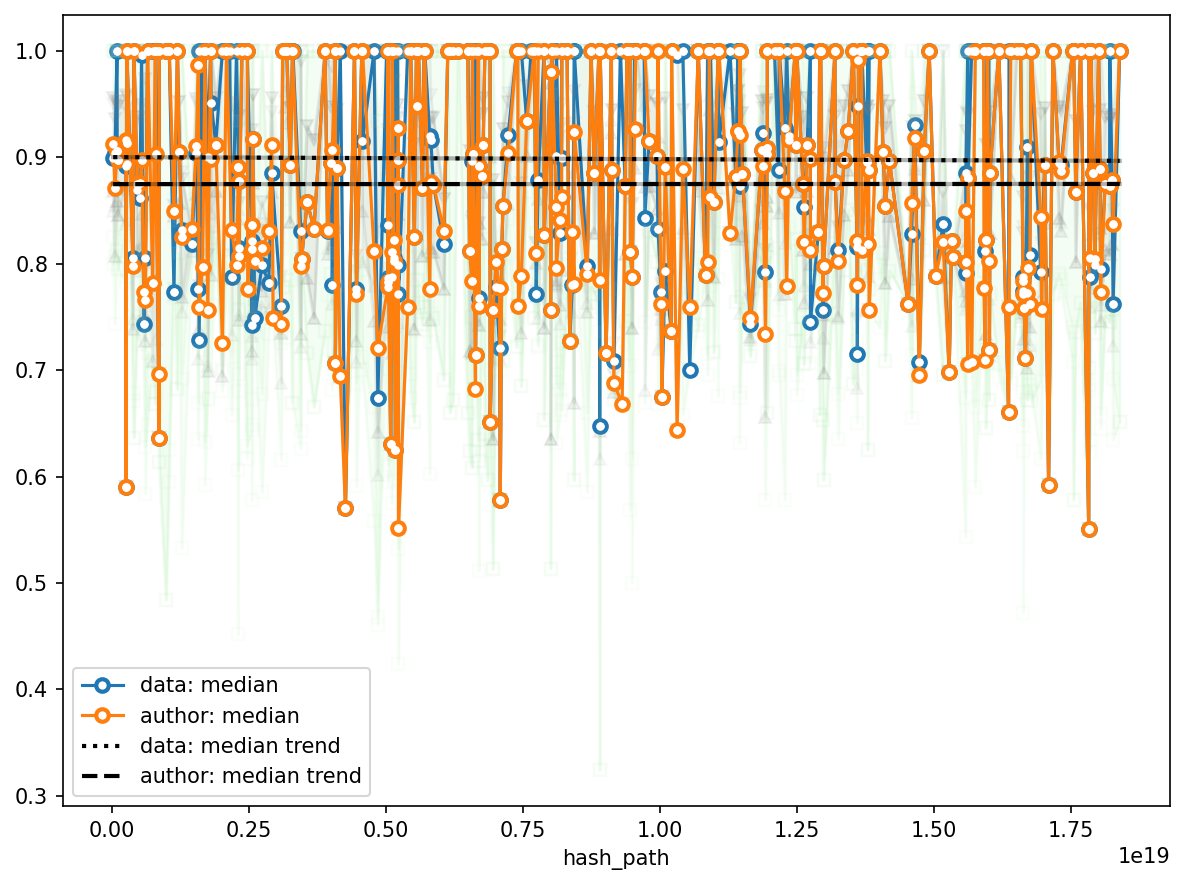

In [91]:
df1 = cons_gt_dwc_t_data_nodes_cos_sim_attributes__path_inspect
df2 = cons_gt_dwc_t_author_nodes_cos_sim_attributes__path_inspect

plt.subplots(figsize=(8,6), dpi=150)

# data
plt.fill_between(df1.index, df1["ds_max"], df1["ds_min"], color="lightgreen", alpha=0.05)
plt.fill_between(df1.index, df1["ds_p75_cont"], df1["ds_p25_cont"], color="gray", alpha=0.05)
df1["ds_p75_cont"].plot(alpha=0.05, marker="v", color="gray", label="", legend=True)
df1["ds_p25_cont"].plot(alpha=0.05, marker="^", color="gray", label="", legend=True)
df1['ds_min'].plot(alpha=0.05, marker="s", markerfacecolor="w", color="lightgreen", label="", legend=True)
df1['ds_max'].plot(alpha=0.05, marker="s", markerfacecolor="w", color="lightgreen", label="", legend=True)
df1['ds_med_cont'].plot(marker="o", markerfacecolor="w", mew=2, label="data: median", legend=True)

# author
plt.fill_between(df2.index, df2["ds_max"], df2["ds_min"], color="lightgreen", alpha=0.05)
plt.fill_between(df2.index, df2["ds_p75_cont"], df2["ds_p25_cont"], color="gray", alpha=0.05)
df2["ds_p75_cont"].plot(alpha=0.1, marker="v", color="gray", label="", legend=True)
df2["ds_p25_cont"].plot(alpha=0.1, marker="^", color="gray", label="", legend=True)
df2['ds_min'].plot(alpha=0.05, marker="s", markerfacecolor="w", color="lightgreen", label="", legend=True)
df2['ds_max'].plot(alpha=0.05, marker="s", markerfacecolor="w", color="lightgreen", label="", legend=True)
df2['ds_med_cont'].plot(marker="o", markerfacecolor="w", mew=2, label="author: median", legend=True)

# trends
m, b = np.polyfit(df1.index, df1['ds_med_cont'], 1)
plt.plot(df1.index, df1['ds_med_cont'], 'w.')
plt.plot(df1.index, m*df1.index+b, '-k', alpha=0.3, markersize=0, lw=2, zorder=100, label="")
plt.plot(df1.index, m*df1.index+b, ':k', markersize=0, lw=2, zorder=100, label="data: median trend")

m, b = np.polyfit(df2.index, df2['ds_med_cont'], 1)
plt.plot(df2.index, df2['ds_med_cont'], 'w.')
plt.plot(df2.index, m*df2.index+b, '-k', alpha=0.3, markersize=0, lw=2, zorder=100, label="")
plt.plot(df2.index, m*df2.index+b, '--k', markersize=0, lw=2, zorder=100, label="author: median trend")

leg = plt.legend(loc="lower left")
plt.tight_layout()
plt.show()

delta_med.shape=(5,)
delta_med.count()=np.int64(5)
5


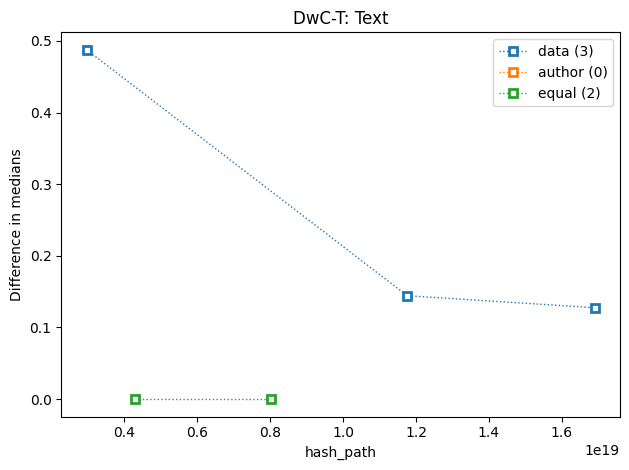


--> top10: data is better:


,ds_med_cont
count,3.000000
mean,0.253197
std,0.203205
min,0.127625
25%,0.135976
50%,0.144327
75%,0.315983
max,0.487639


,path,case_count,ds_count,ds_std_pop,ds_mean,ds_max,ds_min,ds_med_cont,ds_p25_cont,ds_p75_cont,ds_delta_med
hash_path,,,,,,,,,,,
2972828624038042123,{http://rs.tdwg.org/dwc/text/}extension[2]/{ht...,15,15,0.295611,0.735620,1.0,0.257896,1.000000,0.417432,1.000000,0.487639
11761823836042817577,{http://rs.tdwg.org/dwc/text/}extension[3]/{ht...,2,2,0.248102,0.751898,1.0,0.503796,0.751898,0.627847,0.875949,0.144327
16898280223678874349,{http://rs.tdwg.org/dwc/text/}extension[1]/{ht...,15,15,0.268428,0.654307,1.0,0.257896,0.648550,0.417432,1.000000,0.127625


,path,case_count,ds_count,ds_std_pop,ds_mean,ds_max,ds_min,ds_med_cont,ds_p25_cont,ds_p75_cont,ds_delta_med
hash_path,,,,,,,,,,,
11761823836042817577,{http://rs.tdwg.org/dwc/text/}extension[3]/{ht...,2,2,0.040978,0.607572,0.64855,0.566593,0.607572,0.587082,0.628061,0.144327
16898280223678874349,{http://rs.tdwg.org/dwc/text/}extension[1]/{ht...,16,16,0.246570,0.649384,1.00000,0.354693,0.520925,0.497911,1.000000,0.127625
2972828624038042123,{http://rs.tdwg.org/dwc/text/}extension[2]/{ht...,16,16,0.252536,0.638249,1.00000,0.354693,0.512361,0.471848,1.000000,0.487639



--> top10: author is better:


...

,path,case_count,ds_count,ds_std_pop,ds_mean,ds_max,ds_min,ds_med_cont,ds_p25_cont,ds_p75_cont,ds_delta_med
hash_path,,,,,,,,,,,



--> top10: equal:


,ds_med_cont
count,2.0
mean,0.0
std,0.0
min,0.0
25%,0.0
50%,0.0
75%,0.0
max,0.0


,path,case_count,ds_count,ds_std_pop,ds_mean,ds_max,ds_min,ds_med_cont,ds_p25_cont,ds_p75_cont,ds_delta_med
hash_path,,,,,,,,,,,
4300982297047325395,{http://rs.tdwg.org/dwc/text/}extension/{http:...,61,61,0.169136,0.882493,1.0,0.509599,1.0,0.64855,1.0,0.0
8026162855970452193,{http://rs.tdwg.org/dwc/text/}core/{http://rs....,174,174,0.125650,0.948706,1.0,0.509599,1.0,1.00000,1.0,0.0


,path,case_count,ds_count,ds_std_pop,ds_mean,ds_max,ds_min,ds_med_cont,ds_p25_cont,ds_p75_cont,ds_delta_med
hash_path,,,,,,,,,,,
4300982297047325395,{http://rs.tdwg.org/dwc/text/}extension/{http:...,62,62,0.175980,0.856045,1.0,0.509599,1.0,0.64855,1.0,0.0
8026162855970452193,{http://rs.tdwg.org/dwc/text/}core/{http://rs....,174,174,0.138226,0.934567,1.0,0.509599,1.0,1.00000,1.0,0.0


In [92]:
df1 = cons_gt_dwc_t_data_nodes_cos_sim_text__path_inspect
df2 = cons_gt_dwc_t_author_nodes_cos_sim_text__path_inspect

# plt.subplots(figsize=(4.2, 2.8), dpi=300)
plt.title("DwC-T: Text")
plt.ylabel("Difference in medians")

delta_med = (df1["ds_med_cont"] - df2["ds_med_cont"])
print(f"{delta_med.shape=}")
print(f"{delta_med.count()=}")
print(f"{len(set.intersection(set(df1.index), set(df2.index)))}")

df1["ds_delta_med"] = delta_med.dropna()
df2["ds_delta_med"] = delta_med.dropna()

dw = (delta_med[delta_med > 0])
aw = (delta_med[delta_med < 0])
eq = (delta_med[delta_med == 0])
dw.plot(marker="s", markerfacecolor="w", lw=1, ls=":", mew=2, color=mpl.cm.tab10(0), label=f"data ({dw.count()})", legend=True)
aw.plot(marker="s", markerfacecolor="w", lw=1, ls=":", mew=2, color=mpl.cm.tab10(1), label=f"author ({aw.count()})", legend=True)
eq.plot(marker="s", markerfacecolor="w", lw=1, ls=":", mew=2, color=mpl.cm.tab10(2), label=f"equal ({eq.count()})", legend=True)

plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

print("\n--> top10: data is better:")
display(delta_med[delta_med > 0].describe())
data_bs1 = df1.loc[delta_med[delta_med > 0].index]
data_bs2 = df2.loc[delta_med[delta_med > 0].index]
display(data_bs1[data_bs1["case_count"] > 1].sort_values(by=["ds_delta_med"], ascending=False).nlargest(10, columns=["ds_med_cont"]))
display(data_bs2[data_bs2["case_count"] > 1].sort_values(by=["ds_delta_med"], ascending=False).nlargest(10, columns=["ds_med_cont"]))

print("\n--> top10: author is better:")
display(delta_med[delta_med < 0].describe())
author_bs1 = df1.loc[delta_med[delta_med < 0].index]
author_bs2 = df2.loc[delta_med[delta_med < 0].index]
display(author_bs1[author_bs1["case_count"] > 1].sort_values(by=["ds_delta_med"], ascending=False).nlargest(10, columns=["ds_med_cont"]))
display(author_bs2[author_bs2["case_count"] > 1].sort_values(by=["ds_delta_med"], ascending=False).nlargest(10, columns=["ds_med_cont"]))

print("\n--> top10: equal:")
display(delta_med[delta_med == 0].describe())
equal_bs1 = df1.loc[delta_med[delta_med == 0].index]
equal_bs2 = df2.loc[delta_med[delta_med == 0].index]
display(equal_bs1[equal_bs1["case_count"] > 1].sort_values(by=["ds_delta_med"], ascending=False).nlargest(10, columns=["ds_med_cont"]))
display(equal_bs2[equal_bs2["case_count"] > 1].sort_values(by=["ds_delta_med"], ascending=False).nlargest(10, columns=["ds_med_cont"]))

In [93]:
data_bs1[data_bs1["case_count"] > 1]

,path,case_count,ds_count,ds_std_pop,ds_mean,ds_max,ds_min,ds_med_cont,ds_p25_cont,ds_p75_cont,ds_delta_med
hash_path,,,,,,,,,,,
2972828624038042123,{http://rs.tdwg.org/dwc/text/}extension[2]/{ht...,15,15,0.295611,0.735620,1.0,0.257896,1.000000,0.417432,1.000000,0.487639
11761823836042817577,{http://rs.tdwg.org/dwc/text/}extension[3]/{ht...,2,2,0.248102,0.751898,1.0,0.503796,0.751898,0.627847,0.875949,0.144327
16898280223678874349,{http://rs.tdwg.org/dwc/text/}extension[1]/{ht...,15,15,0.268428,0.654307,1.0,0.257896,0.648550,0.417432,1.000000,0.127625


In [94]:
equal_bs2[equal_bs2["case_count"] > 1]

,path,case_count,ds_count,ds_std_pop,ds_mean,ds_max,ds_min,ds_med_cont,ds_p25_cont,ds_p75_cont,ds_delta_med
hash_path,,,,,,,,,,,
4300982297047325395,{http://rs.tdwg.org/dwc/text/}extension/{http:...,62,62,0.175980,0.856045,1.0,0.509599,1.0,0.64855,1.0,0.0
8026162855970452193,{http://rs.tdwg.org/dwc/text/}core/{http://rs....,174,174,0.138226,0.934567,1.0,0.509599,1.0,1.00000,1.0,0.0


delta_med.shape=(329,)
delta_med.count()=np.int64(313)
313


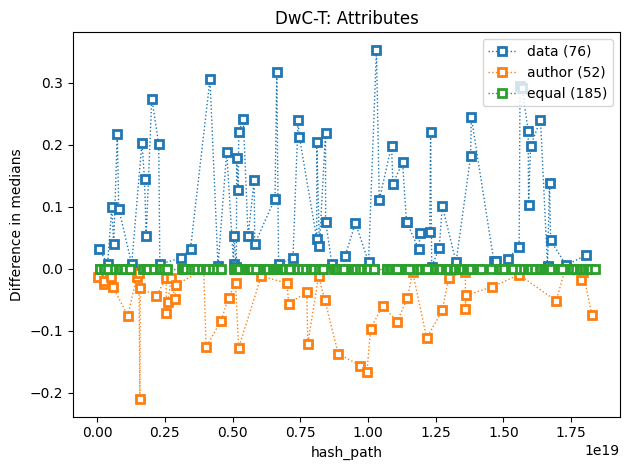


--> top10: data is better:


,ds_med_cont
count,76.000000
mean,0.109241
std,0.098268
min,0.002479
25%,0.019863
50%,0.075455
75%,0.199084
max,0.353021


,path,case_count,ds_count,ds_mean,ds_std_pop,ds_max,ds_min,ds_med_cont,ds_p25_cont,ds_p75_cont,ds_delta_med
hash_path,,,,,,,,,,,
2016192542045894237,{http://rs.tdwg.org/dwc/text/}extension/{http:...,6,6,0.949862,0.112111,1.0,0.699175,1.0,1.000000,1.0,0.274405
8433860910468061834,{http://rs.tdwg.org/dwc/text/}extension/{http:...,11,11,0.883576,0.159098,1.0,0.596415,1.0,0.730395,1.0,0.218991
742685101722019265,{http://rs.tdwg.org/dwc/text/}extension/{http:...,9,9,0.918858,0.116429,1.0,0.708376,1.0,0.782153,1.0,0.217847
7470361097938328380,{http://rs.tdwg.org/dwc/text/}extension/{http:...,19,19,0.892813,0.119535,1.0,0.684725,1.0,0.794702,1.0,0.211890
8110182385437510763,{http://rs.tdwg.org/dwc/text/}extension[2]/{ht...,12,12,0.893328,0.133240,1.0,0.631971,1.0,0.779340,1.0,0.203675
10869558986124723211,{http://rs.tdwg.org/dwc/text/}extension/{http:...,28,28,0.905141,0.107082,1.0,0.715098,1.0,0.796010,1.0,0.198396
16002164154506567750,{http://rs.tdwg.org/dwc/text/}extension/{http:...,11,11,0.901988,0.132001,1.0,0.671569,1.0,0.767245,1.0,0.197154
4783625316611376579,{http://rs.tdwg.org/dwc/text/}extension/{http:...,33,33,0.888208,0.119788,1.0,0.665697,1.0,0.779492,1.0,0.188339
13789952408526950589,{http://rs.tdwg.org/dwc/text/}extension/{http:...,13,13,0.899079,0.119440,1.0,0.625129,1.0,0.815345,1.0,0.181332


,path,case_count,ds_count,ds_mean,ds_std_pop,ds_max,ds_min,ds_med_cont,ds_p25_cont,ds_p75_cont,ds_delta_med
hash_path,,,,,,,,,,,
5574633861900702745,{http://rs.tdwg.org/dwc/text/}extension[1]/{ht...,16,16,0.913234,0.089337,1.000000,0.784835,0.947988,0.827837,1.000000,0.052012
9535927439817200247,{http://rs.tdwg.org/dwc/text/}extension[1]/{ht...,2,2,0.926492,0.073508,1.000000,0.852985,0.926492,0.889739,0.963246,0.073508
11421789015792244818,{http://rs.tdwg.org/dwc/text/}extension[1]/{ht...,2,2,0.924623,0.075377,1.000000,0.849247,0.924623,0.886935,0.962312,0.075377
11428988430704094261,{http://rs.tdwg.org/dwc/text/}extension[1]/{ht...,2,2,0.924467,0.075533,1.000000,0.848933,0.924467,0.886700,0.962233,0.075533
8435489327735267015,{http://rs.tdwg.org/dwc/text/}extension[1]/{ht...,2,2,0.924009,0.075991,1.000000,0.848018,0.924009,0.886014,0.962005,0.075991
14647331967012681332,{http://rs.tdwg.org/dwc/text/}core,174,174,0.909788,0.026783,0.934443,0.837939,0.918513,0.889205,0.934443,0.012229
12353694983162201200,{http://rs.tdwg.org/dwc/text/}core/{http://rs....,2,2,0.916631,0.083369,1.000000,0.833261,0.916631,0.874946,0.958315,0.003364
7229886292365021451,{http://rs.tdwg.org/dwc/text/}core/{http://rs....,2,2,0.904031,0.095969,1.000000,0.808062,0.904031,0.856047,0.952016,0.017108
796597095757983138,{http://rs.tdwg.org/dwc/text/}extension[2]/{ht...,10,10,0.877997,0.121558,1.000000,0.679776,0.903108,0.785853,1.000000,0.096892



--> top10: author is better:


...

,path,case_count,ds_count,ds_mean,ds_std_pop,ds_max,ds_min,ds_med_cont,ds_p25_cont,ds_p75_cont,ds_delta_med
hash_path,,,,,,,,,,,
4571708384884154271,{http://rs.tdwg.org/dwc/text/}extension[1]/{ht...,3,3,0.900009,0.141409,1.0,0.700026,1.000000,0.850013,1.000000,-0.084264
11074962152550503257,{http://rs.tdwg.org/dwc/text/}extension[3]/{ht...,2,2,1.000000,0.000000,1.0,1.000000,1.000000,1.000000,1.000000,-0.085661
12166680672522929366,{http://rs.tdwg.org/dwc/text/}extension[1]/{ht...,3,3,0.898469,0.143586,1.0,0.695408,1.000000,0.847704,1.000000,-0.112042
7778114079761626509,{http://rs.tdwg.org/dwc/text/}extension[1]/{ht...,3,3,0.907339,0.131043,1.0,0.722016,1.000000,0.861008,1.000000,-0.121491
9723819997962796166,{http://rs.tdwg.org/dwc/text/}extension[1]/{ht...,3,3,0.915010,0.120194,1.0,0.745030,1.000000,0.872515,1.000000,-0.157060
9963246539417705938,{http://rs.tdwg.org/dwc/text/}extension[1]/{ht...,3,3,0.945796,0.076656,1.0,0.837388,1.000000,0.918694,1.000000,-0.166887
13620597439594040475,{http://rs.tdwg.org/dwc/text/}core/{http://rs....,2,2,0.991570,0.008430,1.0,0.983139,0.991570,0.987354,0.995785,-0.043085
1577284285756599315,{http://rs.tdwg.org/dwc/text/}extension[1]/{ht...,6,6,0.907248,0.134904,1.0,0.635242,0.986882,0.871718,0.997585,-0.210579
5225386531271955165,{http://rs.tdwg.org/dwc/text/}extension[1]/{ht...,5,5,0.926020,0.069412,1.0,0.819722,0.927292,0.883084,1.000000,-0.128025



--> top10: equal:


,ds_med_cont
count,185.0
mean,0.0
std,0.0
min,0.0
25%,0.0
50%,0.0
75%,0.0
max,0.0


,path,case_count,ds_count,ds_mean,ds_std_pop,ds_max,ds_min,ds_med_cont,ds_p25_cont,ds_p75_cont,ds_delta_med
hash_path,,,,,,,,,,,
272933142033750307,{http://rs.tdwg.org/dwc/text/}extension[1]/{ht...,2,2,1.000000,0.000000,1.0,1.000000,1.0,1.0,1.0,0.0
400177759170725737,{http://rs.tdwg.org/dwc/text/}core/{http://rs....,78,78,0.986643,0.055503,1.0,0.636701,1.0,1.0,1.0,0.0
651642517601736639,{http://rs.tdwg.org/dwc/text/}core/{http://rs....,7,7,0.949745,0.123099,1.0,0.648216,1.0,1.0,1.0,0.0
791856040288621470,{http://rs.tdwg.org/dwc/text/}core/{http://rs....,167,167,0.964891,0.083754,1.0,0.668696,1.0,1.0,1.0,0.0
863956157266005718,{http://rs.tdwg.org/dwc/text/}core/{http://rs....,109,109,0.977398,0.071920,1.0,0.613519,1.0,1.0,1.0,0.0
988448208282033154,{http://rs.tdwg.org/dwc/text/}core/{http://rs....,129,129,0.968353,0.095139,1.0,0.484335,1.0,1.0,1.0,0.0
1046073277701007839,{http://rs.tdwg.org/dwc/text/}core/{http://rs....,112,112,0.975376,0.076584,1.0,0.624742,1.0,1.0,1.0,0.0
1194723424385035108,{http://rs.tdwg.org/dwc/text/}core/{http://rs....,160,160,0.971995,0.071553,1.0,0.682067,1.0,1.0,1.0,0.0
1698159733073129795,{http://rs.tdwg.org/dwc/text/}core/{http://rs....,174,174,0.961873,0.086803,1.0,0.592135,1.0,1.0,1.0,0.0


,path,case_count,ds_count,ds_mean,ds_std_pop,ds_max,ds_min,ds_med_cont,ds_p25_cont,ds_p75_cont,ds_delta_med
hash_path,,,,,,,,,,,
400177759170725737,{http://rs.tdwg.org/dwc/text/}core/{http://rs....,77,77,0.986893,0.054325,1.0,0.636701,1.0,1.0,1.0,0.0
651642517601736639,{http://rs.tdwg.org/dwc/text/}core/{http://rs....,7,7,0.959510,0.099179,1.0,0.716572,1.0,1.0,1.0,0.0
791856040288621470,{http://rs.tdwg.org/dwc/text/}core/{http://rs....,166,166,0.955595,0.092748,1.0,0.668137,1.0,1.0,1.0,0.0
863956157266005718,{http://rs.tdwg.org/dwc/text/}core/{http://rs....,107,107,0.971046,0.079363,1.0,0.613519,1.0,1.0,1.0,0.0
988448208282033154,{http://rs.tdwg.org/dwc/text/}core/{http://rs....,127,127,0.958196,0.105209,1.0,0.484335,1.0,1.0,1.0,0.0
1046073277701007839,{http://rs.tdwg.org/dwc/text/}core/{http://rs....,110,110,0.967780,0.090305,1.0,0.594976,1.0,1.0,1.0,0.0
1194723424385035108,{http://rs.tdwg.org/dwc/text/}core/{http://rs....,158,158,0.962529,0.083758,1.0,0.682067,1.0,1.0,1.0,0.0
1698159733073129795,{http://rs.tdwg.org/dwc/text/}core/{http://rs....,174,174,0.956010,0.090856,1.0,0.632702,1.0,1.0,1.0,0.0
1799432168050510605,{http://rs.tdwg.org/dwc/text/}core/{http://rs....,11,11,0.976926,0.051456,1.0,0.835881,1.0,1.0,1.0,0.0


In [95]:
df1 = cons_gt_dwc_t_data_nodes_cos_sim_attributes__path_inspect
df2 = cons_gt_dwc_t_author_nodes_cos_sim_attributes__path_inspect

# plt.subplots(figsize=(4.2, 3.2), dpi=120)
plt.title("DwC-T: Attributes")
plt.ylabel("Difference in medians")

delta_med = (df1["ds_med_cont"] - df2["ds_med_cont"])
print(f"{delta_med.shape=}")
print(f"{delta_med.count()=}")
print(f"{len(set.intersection(set(df1.index), set(df2.index)))}")

df1["ds_delta_med"] = delta_med.dropna()
df2["ds_delta_med"] = delta_med.dropna()

dw = (delta_med[delta_med > 0])
aw = (delta_med[delta_med < 0])
eq = (delta_med[delta_med == 0])
dw.plot(marker="s", markerfacecolor="w", lw=1, ls=":", mew=2, color=mpl.cm.tab10(0), label=f"data ({dw.count()})", legend=True)
aw.plot(marker="s", markerfacecolor="w", lw=1, ls=":", mew=2, color=mpl.cm.tab10(1), label=f"author ({aw.count()})", legend=True)
eq.plot(marker="s", markerfacecolor="w", lw=1, ls=":", mew=2, color=mpl.cm.tab10(2), label=f"equal ({eq.count()})", legend=True)

plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

print("\n--> top10: data is better:")
display(delta_med[delta_med > 0].describe())
data_bs1 = df1.loc[delta_med[delta_med > 0].index]
data_bs2 = df2.loc[delta_med[delta_med > 0].index]
display(data_bs1[data_bs1["case_count"] > 1].sort_values(by=["ds_delta_med"], ascending=False).nlargest(10, columns=["ds_med_cont"]))
display(data_bs2[data_bs2["case_count"] > 1].sort_values(by=["ds_delta_med"], ascending=False).nlargest(10, columns=["ds_med_cont"]))

print("\n--> top10: author is better:")
display(delta_med[delta_med < 0].describe())
author_bs1 = df1.loc[delta_med[delta_med < 0].index]
author_bs2 = df2.loc[delta_med[delta_med < 0].index]
display(author_bs1[author_bs1["case_count"] > 1].sort_values(by=["ds_delta_med"], ascending=False).nlargest(10, columns=["ds_med_cont"]))
display(author_bs2[author_bs2["case_count"] > 1].sort_values(by=["ds_delta_med"], ascending=False).nlargest(10, columns=["ds_med_cont"]))

print("\n--> top10: equal:")
display(delta_med[delta_med == 0].describe())
equal_bs1 = df1.loc[delta_med[delta_med == 0].index]
equal_bs2 = df2.loc[delta_med[delta_med == 0].index]
display(equal_bs1[equal_bs1["case_count"] > 1].sort_values(by=["ds_delta_med"], ascending=False).nlargest(10, columns=["ds_med_cont"]))
display(equal_bs2[equal_bs2["case_count"] > 1].sort_values(by=["ds_delta_med"], ascending=False).nlargest(10, columns=["ds_med_cont"]))

In [96]:
data_bs1[(data_bs1['ds_delta_med'] >= 0.75 * data_bs1['ds_delta_med'].max())]

,path,case_count,ds_count,ds_mean,ds_std_pop,ds_max,ds_min,ds_med_cont,ds_p25_cont,ds_p75_cont,ds_delta_med
hash_path,,,,,,,,,,,
2016192542045894237,{http://rs.tdwg.org/dwc/text/}extension/{http:...,6,6,0.949862,0.112111,1.000000,0.699175,1.000000,1.000000,1.000000,0.274405
4166473755248203668,{http://rs.tdwg.org/dwc/text/}extension/{http:...,1,1,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.305333
6633044823982244110,{http://rs.tdwg.org/dwc/text/}extension/{http:...,1,1,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.317576
10312634465911785389,{http://rs.tdwg.org/dwc/text/}extension/{http:...,1,1,0.996424,0.000000,0.996424,0.996424,0.996424,0.996424,0.996424,0.353021
15616206012361833326,{http://rs.tdwg.org/dwc/text/}extension/{http:...,1,1,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.294604
15687683872871601652,{http://rs.tdwg.org/dwc/text/}extension/{http:...,1,1,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.292136


In [97]:
author_bs2[(author_bs2['ds_delta_med'] <= 0.7 * author_bs2['ds_delta_med'].min())]

,path,case_count,ds_count,ds_mean,ds_std_pop,ds_max,ds_min,ds_med_cont,ds_p25_cont,ds_p75_cont,ds_delta_med
hash_path,,,,,,,,,,,
1577284285756599315,{http://rs.tdwg.org/dwc/text/}extension[1]/{ht...,6,6,0.907248,0.134904,1.0,0.635242,0.986882,0.871718,0.997585,-0.210579
9723819997962796166,{http://rs.tdwg.org/dwc/text/}extension[1]/{ht...,3,3,0.915010,0.120194,1.0,0.745030,1.000000,0.872515,1.000000,-0.157060
9963246539417705938,{http://rs.tdwg.org/dwc/text/}extension[1]/{ht...,3,3,0.945796,0.076656,1.0,0.837388,1.000000,0.918694,1.000000,-0.166887


In [98]:
data_bs1[data_bs1["path"] == "{http://rs.tdwg.org/dwc/text/}core"]

,path,case_count,ds_count,ds_mean,ds_std_pop,ds_max,ds_min,ds_med_cont,ds_p25_cont,ds_p75_cont,ds_delta_med
hash_path,,,,,,,,,,,
14647331967012681332,{http://rs.tdwg.org/dwc/text/}core,174,174,0.912495,0.02748,0.960939,0.83471,0.930742,0.893119,0.934443,0.012229


In [99]:
data_bs2[data_bs2["path"] == "{http://rs.tdwg.org/dwc/text/}core"]

,path,case_count,ds_count,ds_mean,ds_std_pop,ds_max,ds_min,ds_med_cont,ds_p25_cont,ds_p75_cont,ds_delta_med
hash_path,,,,,,,,,,,
14647331967012681332,{http://rs.tdwg.org/dwc/text/}core,174,174,0.909788,0.026783,0.934443,0.837939,0.918513,0.889205,0.934443,0.012229


In [100]:
%%sql
SELECT
  c.path,
  (c.cons_attributes :: JSON)->'rowType',
  (c.gt_attributes :: JSON)->'rowType',
  AVG(c.cos_sim_attributes),
  COUNT(1)
FROM cons_gt_dwc_t_data_nodes_cos_sim_attributes AS c
WHERE c.path = '{http://rs.tdwg.org/dwc/text/}core'
GROUP BY 1,2,3
ORDER BY 4 DESC, 5

Running query in 'duckdb'

,path,"(CAST(c.cons_attributes AS ""JSON"") -> 'rowType')","(CAST(c.gt_attributes AS ""JSON"") -> 'rowType')",avg(c.cos_sim_attributes),count(1)
0,{http://rs.tdwg.org/dwc/text/}core,"""http://rs.tdwg.org/dwc/terms/Occurrence""","""http://rs.tdwg.org/dwc/terms/Occurrence""",0.923731,111
1,{http://rs.tdwg.org/dwc/text/}core,"""http://rs.tdwg.org/dwc/terms/Taxon""","""http://rs.tdwg.org/dwc/terms/Taxon""",0.922013,5
2,{http://rs.tdwg.org/dwc/text/}core,"""http://rs.tdwg.org/dwc/terms/Event""","""http://rs.tdwg.org/dwc/terms/Event""",0.912074,28
3,{http://rs.tdwg.org/dwc/text/}core,"""http://rs.tdwg.org/dwc/terms/Event""","""http://rs.tdwg.org/dwc/terms/Occurrence""",0.890881,5
4,{http://rs.tdwg.org/dwc/text/}core,"""http://rs.tdwg.org/dwc/terms/Occurrence""","""http://rs.tdwg.org/dwc/terms/Taxon""",0.872423,1
5,{http://rs.tdwg.org/dwc/text/}core,"""http://rs.tdwg.org/dwc/terms/Occurrence""","""http://rs.tdwg.org/dwc/terms/Event""",0.865213,24


In [101]:
%%sql
SELECT
  c.path,
  (c.cons_attributes :: JSON)->'rowType',
  (c.gt_attributes :: JSON)->'rowType',
  AVG(c.cos_sim_attributes),
  COUNT(1)
FROM cons_gt_dwc_t_author_nodes_cos_sim_attributes AS c
WHERE c.path = '{http://rs.tdwg.org/dwc/text/}core'
GROUP BY 1,2,3
ORDER BY 4 DESC, 5

Running query in 'duckdb'

,path,"(CAST(c.cons_attributes AS ""JSON"") -> 'rowType')","(CAST(c.gt_attributes AS ""JSON"") -> 'rowType')",avg(c.cos_sim_attributes),count(1)
0,{http://rs.tdwg.org/dwc/text/}core,"""http://rs.tdwg.org/dwc/terms/Occurrence""","""http://rs.tdwg.org/dwc/terms/Occurrence""",0.920054,113
1,{http://rs.tdwg.org/dwc/text/}core,"""http://rs.tdwg.org/dwc/terms/Taxon""","""http://rs.tdwg.org/dwc/terms/Taxon""",0.912334,6
2,{http://rs.tdwg.org/dwc/text/}core,"""http://rs.tdwg.org/dwc/terms/Event""","""http://rs.tdwg.org/dwc/terms/Event""",0.909287,23
3,{http://rs.tdwg.org/dwc/text/}core,"""http://rs.tdwg.org/dwc/terms/Occurrence""","""http://rs.tdwg.org/dwc/terms/Event""",0.873453,31
4,{http://rs.tdwg.org/dwc/text/}core,"""http://rs.tdwg.org/dwc/terms/Occurrence""","""http://rs.tdwg.org/dwc/terms/Taxon""",0.872423,1


### EML

In [145]:
%%sql cons_gt_eml_data_nodes_cos_sim_text__path_inspect <<
CREATE TABLE IF NOT EXISTS cons_gt_eml_data_nodes_cos_sim_text__path_inspect AS (
  SELECT
    c.path,
    hash(c.path) AS hash_path,
    COUNT(case_id) as case_count,
    COUNT(cos_sim_text) as ds_count,
    stddev_pop(cos_sim_text) as ds_std_pop,
    AVG(cos_sim_text) as ds_mean,
    MAX(cos_sim_text) as ds_max,
    MIN(cos_sim_text) as ds_min,
    PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY cos_sim_text) AS ds_med_cont,
    PERCENTILE_CONT(0.25) WITHIN GROUP (ORDER BY cos_sim_text) AS ds_p25_cont,
    PERCENTILE_CONT(0.75) WITHIN GROUP (ORDER BY cos_sim_text) AS ds_p75_cont,
  FROM cons_gt_eml_data_nodes_cos_sim_text as c
  GROUP BY c.path, hash_path
);
SELECT * FROM cons_gt_eml_data_nodes_cos_sim_text__path_inspect;

Running query in 'duckdb'

In [147]:
%%sql cons_gt_eml_data_nodes_cos_sim_attributes__path_inspect <<
CREATE TABLE IF NOT EXISTS cons_gt_eml_data_nodes_cos_sim_attributes__path_inspect AS (
  SELECT
    c.path,
    hash(c.path) AS hash_path,
    COUNT(case_id) as case_count,
    COUNT(cos_sim_attributes) as ds_count,
    stddev_pop(cos_sim_attributes) as ds_std_pop,
    AVG(cos_sim_attributes) as ds_mean,
    MAX(cos_sim_attributes) as ds_max,
    MIN(cos_sim_attributes) as ds_min,
    PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY cos_sim_attributes) AS ds_med_cont,
    PERCENTILE_CONT(0.25) WITHIN GROUP (ORDER BY cos_sim_attributes) AS ds_p25_cont,
    PERCENTILE_CONT(0.75) WITHIN GROUP (ORDER BY cos_sim_attributes) AS ds_p75_cont,
  FROM cons_gt_eml_data_nodes_cos_sim_attributes as c
  GROUP BY c.path, hash_path
);
SELECT * FROM cons_gt_eml_data_nodes_cos_sim_attributes__path_inspect;

Running query in 'duckdb'

In [148]:
%%sql cons_gt_eml_author_nodes_cos_sim_text__path_inspect <<
CREATE TABLE IF NOT EXISTS cons_gt_eml_author_nodes_cos_sim_text__path_inspect AS (
  SELECT
    c.path,
    hash(c.path) AS hash_path,
    COUNT(case_id) as case_count,
    COUNT(cos_sim_text) as ds_count,
    stddev_pop(cos_sim_text) as ds_std_pop,
    AVG(cos_sim_text) as ds_mean,
    MAX(cos_sim_text) as ds_max,
    MIN(cos_sim_text) as ds_min,
    PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY cos_sim_text) AS ds_med_cont,
    PERCENTILE_CONT(0.25) WITHIN GROUP (ORDER BY cos_sim_text) AS ds_p25_cont,
    PERCENTILE_CONT(0.75) WITHIN GROUP (ORDER BY cos_sim_text) AS ds_p75_cont,
  FROM cons_gt_eml_author_nodes_cos_sim_text as c
  GROUP BY c.path, hash_path
);
SELECT * FROM cons_gt_eml_author_nodes_cos_sim_text__path_inspect;

Running query in 'duckdb'

In [149]:
%%sql cons_gt_eml_author_nodes_cos_sim_attributes__path_inspect <<
CREATE TABLE IF NOT EXISTS cons_gt_eml_author_nodes_cos_sim_attributes__path_inspect AS (
  SELECT
    c.path,
    hash(c.path) AS hash_path,
    COUNT(case_id) as case_count,
    COUNT(cos_sim_attributes) as ds_count,
    stddev_pop(cos_sim_attributes) as ds_std_pop,
    AVG(cos_sim_attributes) as ds_mean,
    MAX(cos_sim_attributes) as ds_max,
    MIN(cos_sim_attributes) as ds_min,
    PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY cos_sim_attributes) AS ds_med_cont,
    PERCENTILE_CONT(0.25) WITHIN GROUP (ORDER BY cos_sim_attributes) AS ds_p25_cont,
    PERCENTILE_CONT(0.75) WITHIN GROUP (ORDER BY cos_sim_attributes) AS ds_p75_cont,
  FROM cons_gt_eml_author_nodes_cos_sim_attributes as c
  GROUP BY c.path, hash_path
);
SELECT * FROM cons_gt_eml_author_nodes_cos_sim_attributes__path_inspect;

Running query in 'duckdb'

In [150]:
cons_gt_eml_data_nodes_cos_sim_text__path_inspect = (
    cons_gt_eml_data_nodes_cos_sim_text__path_inspect.sort_values(by="hash_path").set_index("hash_path")
)
cons_gt_eml_data_nodes_cos_sim_attributes__path_inspect = (
    cons_gt_eml_data_nodes_cos_sim_attributes__path_inspect.sort_values(by="hash_path").set_index("hash_path")
)
cons_gt_eml_author_nodes_cos_sim_text__path_inspect = (
    cons_gt_eml_author_nodes_cos_sim_text__path_inspect.sort_values(by="hash_path").set_index("hash_path")
)
cons_gt_eml_author_nodes_cos_sim_attributes__path_inspect = (
    cons_gt_eml_author_nodes_cos_sim_attributes__path_inspect.sort_values(by="hash_path").set_index("hash_path")
)

In [151]:
set(cons_gt_eml_data_nodes_cos_sim_text__path_inspect["path"].unique()) == set(cons_gt_eml_author_nodes_cos_sim_text__path_inspect["path"].unique())

False

In [152]:
set(cons_gt_eml_data_nodes_cos_sim_attributes__path_inspect["path"].unique()) == set(cons_gt_eml_author_nodes_cos_sim_attributes__path_inspect["path"].unique())

False

In [153]:
print(f"{cons_gt_eml_data_nodes_cos_sim_text__path_inspect.shape=}")
print(f"{cons_gt_eml_data_nodes_cos_sim_attributes__path_inspect.shape=}")

print(f"{cons_gt_eml_author_nodes_cos_sim_text__path_inspect.shape=}")
print(f"{cons_gt_eml_author_nodes_cos_sim_attributes__path_inspect.shape=}")


cons_gt_eml_data_nodes_cos_sim_text__path_inspect.shape=(46, 10)
cons_gt_eml_data_nodes_cos_sim_attributes__path_inspect.shape=(5, 10)
cons_gt_eml_author_nodes_cos_sim_text__path_inspect.shape=(29, 10)
cons_gt_eml_author_nodes_cos_sim_attributes__path_inspect.shape=(3, 10)


In [164]:
%%sql
SELECT c.path, ds_mean, ds_count
FROM cons_gt_eml_data_nodes_cos_sim_text__path_inspect AS c
ORDER BY c.path;

Running query in 'duckdb'

,path,ds_mean,ds_count
0,dataset/abstract/para,0.426243,11
1,dataset/contact/electronicMailAddress,0.054053,1
2,dataset/contact/individualName/givenName,1.000000,1
3,dataset/contact/individualName/surName,1.000000,1
4,dataset/coverage/geographicCoverage/geographic...,0.665401,1
5,dataset/coverage/temporalCoverage/rangeOfDates...,1.000000,1
6,dataset/coverage/temporalCoverage/rangeOfDates...,1.000000,1
7,dataset/creator/individualName/givenName,0.094476,1
8,dataset/creator/individualName/surName,0.282708,30
9,dataset/creator/userId,0.196024,17


In [163]:
%%sql
SELECT c.path, ds_mean, ds_count
FROM cons_gt_eml_author_nodes_cos_sim_text__path_inspect AS c
ORDER BY c.path;

Running query in 'duckdb'

,path,ds_mean,ds_count
0,dataset/abstract/para,0.414720,7
1,dataset/contact/electronicMailAddress,0.152196,1
2,dataset/contact/individualName/surName,0.081286,1
3,dataset/coverage/geographicCoverage/geographic...,0.569407,2
4,dataset/creator/individualName/surName,0.332244,28
5,dataset/creator/userId,0.200261,17
6,dataset/intellectualRights/para,0.412951,1
7,dataset/maintenance/description/para,0.381276,8
8,dataset/maintenance/maintenanceUpdateFrequency,0.178412,142
9,dataset/methods/methodStep/description/para,0.298746,72


In [162]:
%%sql
SELECT c.path, ds_mean, ds_count
FROM cons_gt_eml_data_nodes_cos_sim_attributes__path_inspect AS c
ORDER BY c.path;

Running query in 'duckdb'

,path,ds_mean,ds_count
0,.,0.518817,150
1,dataset/creator/userId,0.952133,17
2,dataset/creator[1]/userId,0.990047,1
3,dataset/creator[2]/userId,0.990047,1
4,dataset/project/studyAreaDescription/descriptor,0.794280,11


In [165]:
%%sql
SELECT c.path, ds_mean, ds_count
FROM cons_gt_eml_author_nodes_cos_sim_attributes__path_inspect AS c
ORDER BY c.path;

Running query in 'duckdb'

,path,ds_mean,ds_count
0,.,0.534112,148
1,dataset/creator/userId,0.952133,17
2,dataset/project/studyAreaDescription/descriptor,0.787834,11


#### Inspections EML

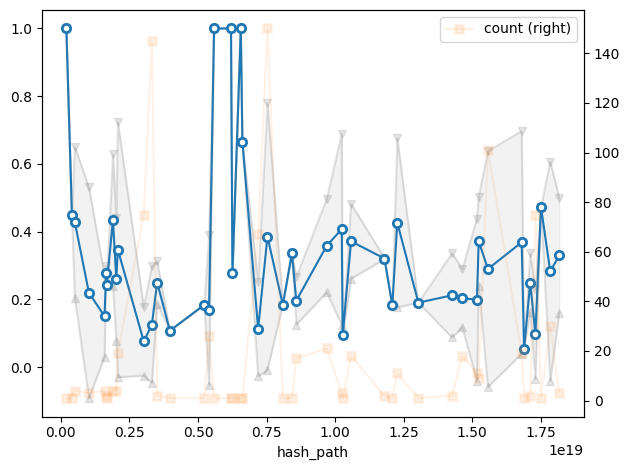

In [110]:
df = cons_gt_eml_data_nodes_cos_sim_text__path_inspect
mean_plus_std = (df['ds_mean'] + df['ds_std_pop'])
mean_min_std = (df['ds_mean'] - df['ds_std_pop'])

plt.fill_between(df.index, mean_min_std, mean_plus_std, color="gray", alpha=0.1)
mean_plus_std.plot(alpha=0.2, marker="v", color="gray")
mean_min_std.plot(alpha=0.2, marker="^", color="gray")
df['ds_mean'].plot(marker="o", markerfacecolor="w", mew=2)
df['ds_count'].plot(alpha=0.1, marker="s", mew=2, secondary_y=True, label="count", legend=True)


plt.tight_layout()

<Axes: xlabel='hash_path'>

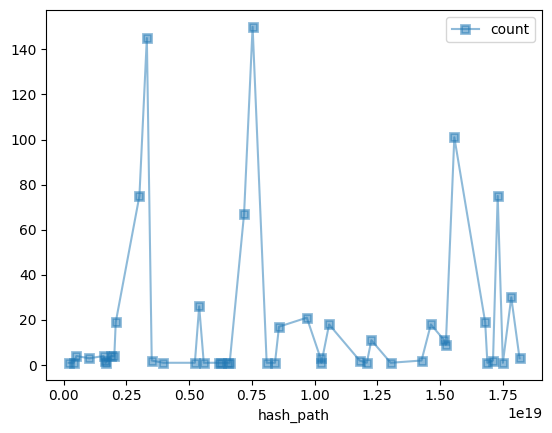

In [111]:
df = cons_gt_eml_data_nodes_cos_sim_text__path_inspect
df['ds_count'].plot(alpha=0.5, marker="s", mew=2, label="count", legend=True)

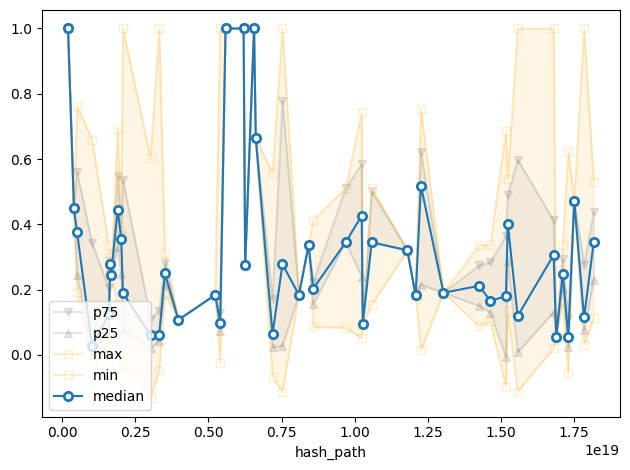

In [112]:
df = cons_gt_eml_data_nodes_cos_sim_text__path_inspect
plt.fill_between(df.index, df["ds_max"], df["ds_min"], color="orange", alpha=0.1)
plt.fill_between(df.index, df["ds_p75_cont"], df["ds_p25_cont"], color="gray", alpha=0.1)
df["ds_p75_cont"].plot(alpha=0.2, marker="v", color="gray", label="p75", legend=True)
df["ds_p25_cont"].plot(alpha=0.2, marker="^", color="gray", label="p25", legend=True)
df['ds_min'].plot(alpha=0.2, marker="s", markerfacecolor="w", color="orange", label="max", legend=True)
df['ds_max'].plot(alpha=0.2, marker="s", markerfacecolor="w", color="orange", label="min", legend=True)
df['ds_med_cont'].plot(marker="o", markerfacecolor="w", mew=2, label="median", legend=True)

plt.legend(loc="lower left")
plt.tight_layout()
plt.show()

<Axes: xlabel='hash_path'>

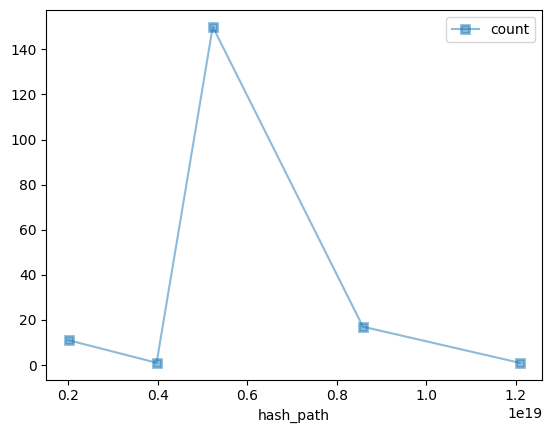

In [113]:
df = cons_gt_eml_data_nodes_cos_sim_attributes__path_inspect
df['ds_count'].plot(alpha=0.5, marker="s", mew=2, label="count", legend=True)

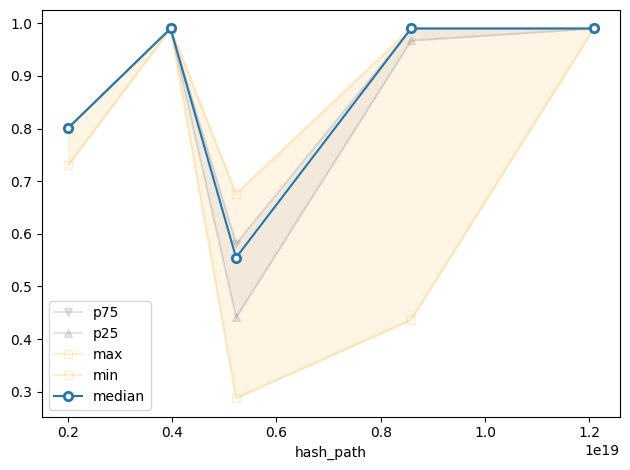

In [114]:
df = cons_gt_eml_data_nodes_cos_sim_attributes__path_inspect
plt.fill_between(df.index, df["ds_max"], df["ds_min"], color="orange", alpha=0.1)
plt.fill_between(df.index, df["ds_p75_cont"], df["ds_p25_cont"], color="gray", alpha=0.1)
df["ds_p75_cont"].plot(alpha=0.2, marker="v", color="gray", label="p75", legend=True)
df["ds_p25_cont"].plot(alpha=0.2, marker="^", color="gray", label="p25", legend=True)
df['ds_min'].plot(alpha=0.2, marker="s", markerfacecolor="w", color="orange", label="max", legend=True)
df['ds_max'].plot(alpha=0.2, marker="s", markerfacecolor="w", color="orange", label="min", legend=True)
df['ds_med_cont'].plot(marker="o", markerfacecolor="w", mew=2, label="median", legend=True)

plt.legend(loc="lower left")
plt.tight_layout()
plt.show()

<Axes: xlabel='hash_path'>

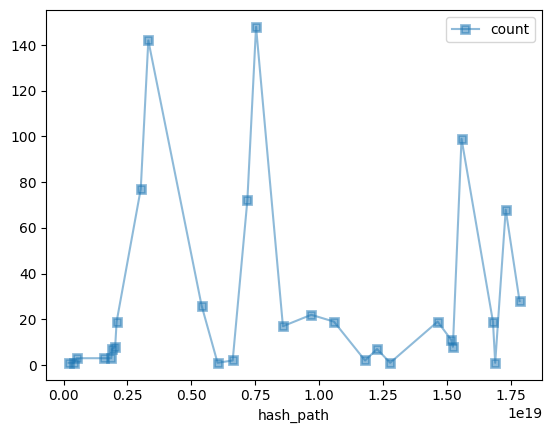

In [115]:
df = cons_gt_eml_author_nodes_cos_sim_text__path_inspect
df['ds_count'].plot(alpha=0.5, marker="s", mew=2, label="count", legend=True)

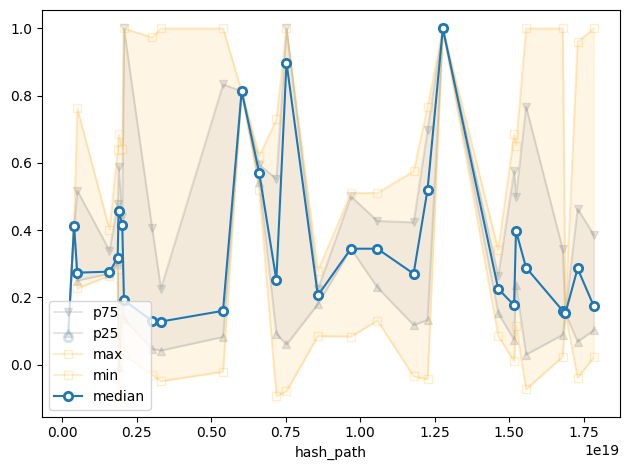

In [116]:
df = cons_gt_eml_author_nodes_cos_sim_text__path_inspect
plt.fill_between(df.index, df["ds_max"], df["ds_min"], color="orange", alpha=0.1)
plt.fill_between(df.index, df["ds_p75_cont"], df["ds_p25_cont"], color="gray", alpha=0.1)
df["ds_p75_cont"].plot(alpha=0.2, marker="v", color="gray", label="p75", legend=True)
df["ds_p25_cont"].plot(alpha=0.2, marker="^", color="gray", label="p25", legend=True)
df['ds_min'].plot(alpha=0.2, marker="s", markerfacecolor="w", color="orange", label="max", legend=True)
df['ds_max'].plot(alpha=0.2, marker="s", markerfacecolor="w", color="orange", label="min", legend=True)
df['ds_med_cont'].plot(marker="o", markerfacecolor="w", mew=2, label="median", legend=True)

plt.legend(loc="lower left")
plt.tight_layout()
plt.show()

<Axes: xlabel='hash_path'>

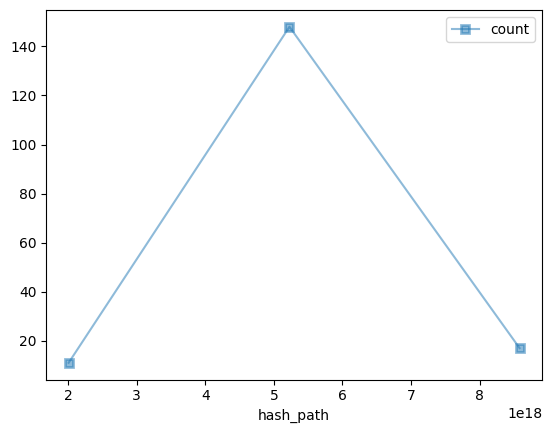

In [117]:
df = cons_gt_eml_author_nodes_cos_sim_attributes__path_inspect
df['ds_count'].plot(alpha=0.5, marker="s", mew=2, label="count", legend=True)

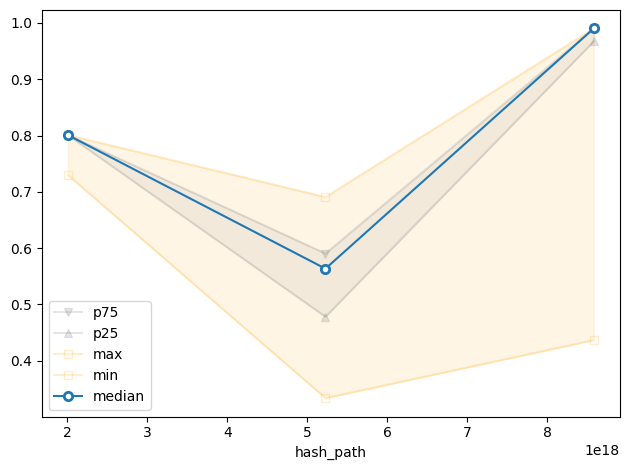

In [118]:
df = cons_gt_eml_author_nodes_cos_sim_attributes__path_inspect
plt.fill_between(df.index, df["ds_max"], df["ds_min"], color="orange", alpha=0.1)
plt.fill_between(df.index, df["ds_p75_cont"], df["ds_p25_cont"], color="gray", alpha=0.1)
df["ds_p75_cont"].plot(alpha=0.2, marker="v", color="gray", label="p75", legend=True)
df["ds_p25_cont"].plot(alpha=0.2, marker="^", color="gray", label="p25", legend=True)
df['ds_min'].plot(alpha=0.2, marker="s", markerfacecolor="w", color="orange", label="max", legend=True)
df['ds_max'].plot(alpha=0.2, marker="s", markerfacecolor="w", color="orange", label="min", legend=True)
df['ds_med_cont'].plot(marker="o", markerfacecolor="w", mew=2, label="median", legend=True)

plt.legend(loc="lower left")
plt.tight_layout()
plt.show()

#### Compare DwC-T Data vs Author



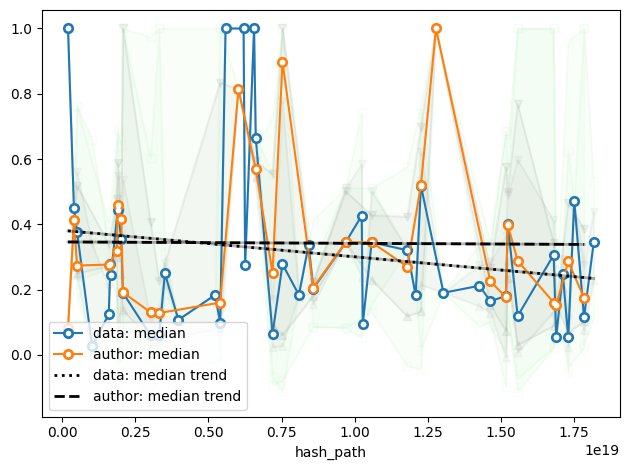

In [119]:
df1 = cons_gt_eml_data_nodes_cos_sim_text__path_inspect
df2 = cons_gt_eml_author_nodes_cos_sim_text__path_inspect

# data
plt.fill_between(df1.index, df1["ds_max"], df1["ds_min"], color="lightgreen", alpha=0.05)
plt.fill_between(df1.index, df1["ds_p75_cont"], df1["ds_p25_cont"], color="gray", alpha=0.05)
df1["ds_p75_cont"].plot(alpha=0.05, marker="v", color="gray", label="", legend=True)
df1["ds_p25_cont"].plot(alpha=0.05, marker="^", color="gray", label="", legend=True)
df1['ds_min'].plot(alpha=0.05, marker="s", markerfacecolor="w", color="lightgreen", label="", legend=True)
df1['ds_max'].plot(alpha=0.05, marker="s", markerfacecolor="w", color="lightgreen", label="", legend=True)
df1['ds_med_cont'].plot(marker="o", markerfacecolor="w", mew=2, label="data: median", legend=True)

# author
plt.fill_between(df2.index, df2["ds_max"], df2["ds_min"], color="lightgreen", alpha=0.05)
plt.fill_between(df2.index, df2["ds_p75_cont"], df2["ds_p25_cont"], color="gray", alpha=0.05)
df2["ds_p75_cont"].plot(alpha=0.1, marker="v", color="gray", label="", legend=True)
df2["ds_p25_cont"].plot(alpha=0.1, marker="^", color="gray", label="", legend=True)
df2['ds_min'].plot(alpha=0.05, marker="s", markerfacecolor="w", color="lightgreen", label="", legend=True)
df2['ds_max'].plot(alpha=0.05, marker="s", markerfacecolor="w", color="lightgreen", label="", legend=True)
df2['ds_med_cont'].plot(marker="o", markerfacecolor="w", mew=2, label="author: median", legend=True)

# trends
m, b = np.polyfit(df1.index, df1['ds_med_cont'], 1)
plt.plot(df1.index, df1['ds_med_cont'], 'w.')
plt.plot(df1.index, m*df1.index+b, '-k', alpha=0.3, markersize=0, lw=2, zorder=100, label="")
plt.plot(df1.index, m*df1.index+b, ':k', markersize=0, lw=2, zorder=100, label="data: median trend")

m, b = np.polyfit(df2.index, df2['ds_med_cont'], 1)
plt.plot(df2.index, df2['ds_med_cont'], 'w.')
plt.plot(df2.index, m*df2.index+b, '-k', alpha=0.3, markersize=0, lw=2, zorder=100, label="")
plt.plot(df2.index, m*df2.index+b, '--k', markersize=0, lw=2, zorder=100, label="author: median trend")

leg = plt.legend(loc="lower left")
plt.tight_layout()
plt.show()

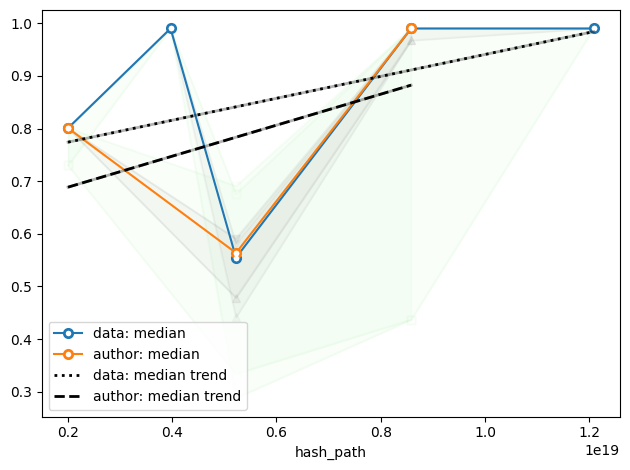

In [120]:
df1 = cons_gt_eml_data_nodes_cos_sim_attributes__path_inspect
df2 = cons_gt_eml_author_nodes_cos_sim_attributes__path_inspect

# data
plt.fill_between(df1.index, df1["ds_max"], df1["ds_min"], color="lightgreen", alpha=0.05)
plt.fill_between(df1.index, df1["ds_p75_cont"], df1["ds_p25_cont"], color="gray", alpha=0.05)
df1["ds_p75_cont"].plot(alpha=0.05, marker="v", color="gray", label="", legend=True)
df1["ds_p25_cont"].plot(alpha=0.05, marker="^", color="gray", label="", legend=True)
df1['ds_min'].plot(alpha=0.05, marker="s", markerfacecolor="w", color="lightgreen", label="", legend=True)
df1['ds_max'].plot(alpha=0.05, marker="s", markerfacecolor="w", color="lightgreen", label="", legend=True)
df1['ds_med_cont'].plot(marker="o", markerfacecolor="w", mew=2, label="data: median", legend=True)

# author
plt.fill_between(df2.index, df2["ds_max"], df2["ds_min"], color="lightgreen", alpha=0.05)
plt.fill_between(df2.index, df2["ds_p75_cont"], df2["ds_p25_cont"], color="gray", alpha=0.05)
df2["ds_p75_cont"].plot(alpha=0.1, marker="v", color="gray", label="", legend=True)
df2["ds_p25_cont"].plot(alpha=0.1, marker="^", color="gray", label="", legend=True)
df2['ds_min'].plot(alpha=0.05, marker="s", markerfacecolor="w", color="lightgreen", label="", legend=True)
df2['ds_max'].plot(alpha=0.05, marker="s", markerfacecolor="w", color="lightgreen", label="", legend=True)
df2['ds_med_cont'].plot(marker="o", markerfacecolor="w", mew=2, label="author: median", legend=True)

# trends
m, b = np.polyfit(df1.index, df1['ds_med_cont'], 1)
plt.plot(df1.index, df1['ds_med_cont'], 'w.')
plt.plot(df1.index, m*df1.index+b, '-k', alpha=0.3, markersize=0, lw=2, zorder=100, label="")
plt.plot(df1.index, m*df1.index+b, ':k', markersize=0, lw=2, zorder=100, label="data: median trend")

m, b = np.polyfit(df2.index, df2['ds_med_cont'], 1)
plt.plot(df2.index, df2['ds_med_cont'], 'w.')
plt.plot(df2.index, m*df2.index+b, '-k', alpha=0.3, markersize=0, lw=2, zorder=100, label="")
plt.plot(df2.index, m*df2.index+b, '--k', markersize=0, lw=2, zorder=100, label="author: median trend")

leg = plt.legend(loc="lower left")
plt.tight_layout()
plt.show()

delta_med.shape=(49,)
delta_med.count()=np.int64(26)
26


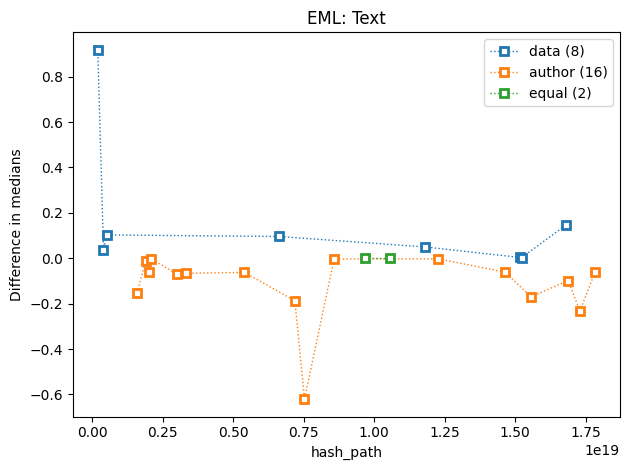


--> top10: data is better:


,ds_med_cont
count,8.000000
mean,0.169367
std,0.306902
min,0.002733
25%,0.027514
50%,0.073018
75%,0.113471
max,0.918714


,path,case_count,ds_count,ds_std_pop,ds_mean,ds_max,ds_min,ds_med_cont,ds_p25_cont,ds_p75_cont
hash_path,,,,,,,,,,
199826611885047600,dataset/contact/individualName/surName,1,1,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
6617235638686593906,dataset/coverage/geographicCoverage/geographic...,1,1,0.000000,0.665401,0.665401,0.665401,0.665401,0.665401,0.665401
402660203177841723,dataset/intellectualRights/para,1,1,0.000000,0.448450,0.448450,0.448450,0.448450,0.448450,0.448450
15232234705173613974,dataset/maintenance/description/para,9,9,0.132041,0.371394,0.537902,0.134096,0.400889,0.286467,0.489912
509835330926488103,dataset/project/personnel[3]/individualName/su...,4,4,0.223230,0.426960,0.762364,0.192765,0.376356,0.243538,0.559777
11797055351399041090,dataset/project/abstract/para,2,2,0.001916,0.320464,0.322380,0.318549,0.320464,0.319507,0.321422
16800044395398089788,dataset/project/personnel[2]/individualName/su...,19,19,0.328631,0.368428,1.000000,0.020328,0.305944,0.131395,0.411671
15168855418924349169,dataset/project/studyAreaDescription/descripto...,11,11,0.239744,0.198573,0.686205,-0.097718,0.180205,-0.006564,0.363356


,path,case_count,ds_count,ds_std_pop,ds_mean,ds_max,ds_min,ds_med_cont,ds_p25_cont,ds_p75_cont
hash_path,,,,,,,,,,
6617235638686593906,dataset/coverage/geographicCoverage/geographic...,2,2,0.051234,0.569407,0.620641,0.518173,0.569407,0.543790,0.595024
402660203177841723,dataset/intellectualRights/para,1,1,0.000000,0.412951,0.412951,0.412951,0.412951,0.412951,0.412951
15232234705173613974,dataset/maintenance/description/para,8,8,0.166266,0.381276,0.650771,0.116382,0.398156,0.236761,0.499825
509835330926488103,dataset/project/personnel[3]/individualName/su...,3,3,0.242257,0.420840,0.762364,0.226543,0.273612,0.250078,0.517988
11797055351399041090,dataset/project/abstract/para,2,2,0.305234,0.270422,0.575656,-0.034811,0.270422,0.117806,0.423039
15168855418924349169,dataset/project/studyAreaDescription/descripto...,11,11,0.258000,0.302037,0.685300,0.009979,0.176647,0.073826,0.575361
16800044395398089788,dataset/project/personnel[2]/individualName/su...,19,19,0.277738,0.274574,1.000000,0.023779,0.160292,0.088975,0.343256
199826611885047600,dataset/contact/individualName/surName,1,1,0.000000,0.081286,0.081286,0.081286,0.081286,0.081286,0.081286



--> top10: author is better:


...

,path,case_count,ds_count,ds_std_pop,ds_mean,ds_max,ds_min,ds_med_cont,ds_p25_cont,ds_p75_cont
hash_path,,,,,,,,,,
7531383348528985230,dataset/title,148,148,0.432444,0.627410,1.000000,-0.078825,0.898597,0.059959,1.000000
12264083121720851709,dataset/abstract/para,7,7,0.318298,0.414720,0.765518,-0.043659,0.520462,0.133193,0.697164
1897832894039290149,dataset/methods/methodStep[1]/description/para,7,7,0.313033,0.315588,0.685324,-0.099529,0.458055,-0.006215,0.588847
2019908457384792944,dataset/methods/methodStep[2]/description/para,8,8,0.164871,0.356656,0.641698,0.131138,0.416618,0.193975,0.437744
15570285937076544010,dataset/project/title,99,99,0.382659,0.402375,1.000000,-0.073552,0.288596,0.029993,0.767225
17299146993214317173,dataset/methods/qualityControl/description/para,68,68,0.262506,0.288214,0.959999,-0.039400,0.286073,0.068427,0.463870
1591939635604457060,dataset/project/personnel[3]/role,3,3,0.061981,0.314523,0.401923,0.265040,0.276606,0.270823,0.339264
7191309023196111392,dataset/methods/methodStep/description/para,72,72,0.243753,0.298746,0.729353,-0.094472,0.251303,0.091747,0.552717
14635275423761931014,dataset/project/personnel[2]/role,19,19,0.077124,0.217014,0.341561,0.085831,0.225492,0.152788,0.264587



--> top10: equal:


,ds_med_cont
count,2.0
mean,0.0
std,0.0
min,0.0
25%,0.0
50%,0.0
75%,0.0
max,0.0


,path,case_count,ds_count,ds_std_pop,ds_mean,ds_max,ds_min,ds_med_cont,ds_p25_cont,ds_p75_cont
hash_path,,,,,,,,,,
9691641318081825809,dataset/project/personnel/role,21,21,0.137727,0.358203,0.51054,0.083198,0.344871,0.344871,0.510540
10579610229072948010,dataset/project/personnel[1]/role,18,18,0.110259,0.371270,0.51054,0.152777,0.344871,0.344871,0.500554


,path,case_count,ds_count,ds_std_pop,ds_mean,ds_max,ds_min,ds_med_cont,ds_p25_cont,ds_p75_cont
hash_path,,,,,,,,,,
9691641318081825809,dataset/project/personnel/role,22,22,0.126390,0.360871,0.51054,0.083198,0.344871,0.344871,0.500554
10579610229072948010,dataset/project/personnel[1]/role,19,19,0.130121,0.324028,0.51054,0.131206,0.344871,0.229844,0.427706


In [226]:
df1 = cons_gt_eml_data_nodes_cos_sim_text__path_inspect
df2 = cons_gt_eml_author_nodes_cos_sim_text__path_inspect

# plt.subplots(figsize=(4.2, 2.8), dpi=300)
plt.title("EML: Text")
plt.ylabel("Difference in medians")

delta_med = (df1["ds_med_cont"] - df2["ds_med_cont"])
print(f"{delta_med.shape=}")
print(f"{delta_med.count()=}")
print(f"{len(set.intersection(set(df1.index), set(df2.index)))}")


dw = (delta_med[delta_med > 0])
aw = (delta_med[delta_med < 0])
eq = (delta_med[delta_med == 0])
dw.plot(marker="s", markerfacecolor="w", lw=1, ls=":", mew=2, color=mpl.cm.tab10(0), label=f"data ({dw.count()})", legend=True)
aw.plot(marker="s", markerfacecolor="w", lw=1, ls=":", mew=2, color=mpl.cm.tab10(1), label=f"author ({aw.count()})", legend=True)
eq.plot(marker="s", markerfacecolor="w", lw=1, ls=":", mew=2, color=mpl.cm.tab10(2), label=f"equal ({eq.count()})", legend=True)

plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

print("\n--> top10: data is better:")
display(delta_med[delta_med > 0].describe())
data_bs1 = df1.loc[delta_med[delta_med > 0].index]
data_bs2 = df2.loc[delta_med[delta_med > 0].index]
display(data_bs1[data_bs1["case_count"] > 0].nlargest(10, columns=["ds_med_cont"]))
display(data_bs2[data_bs2["case_count"] > 0].nlargest(10, columns=["ds_med_cont"]))

print("\n--> top10: author is better:")
display(delta_med[delta_med < 0].describe())
author_bs1 = df1.loc[delta_med[delta_med < 0].index]
author_bs2 = df2.loc[delta_med[delta_med < 0].index]
display(author_bs1[author_bs1["case_count"] > 0].nlargest(10, columns=["ds_med_cont"]))
display(author_bs2[author_bs2["case_count"] > 0].nlargest(10, columns=["ds_med_cont"]))

print("\n--> top10: equal:")
display(delta_med[delta_med == 0].describe())
equal_bs1 = df1.loc[delta_med[delta_med == 0].index]
equal_bs2 = df2.loc[delta_med[delta_med == 0].index]
display(equal_bs1[equal_bs1["case_count"] > 0].nlargest(10, columns=["ds_med_cont"]))
display(equal_bs2[equal_bs2["case_count"] > 0].nlargest(10, columns=["ds_med_cont"]))

delta_med.shape=(5,)
delta_med.count()=np.int64(3)
3


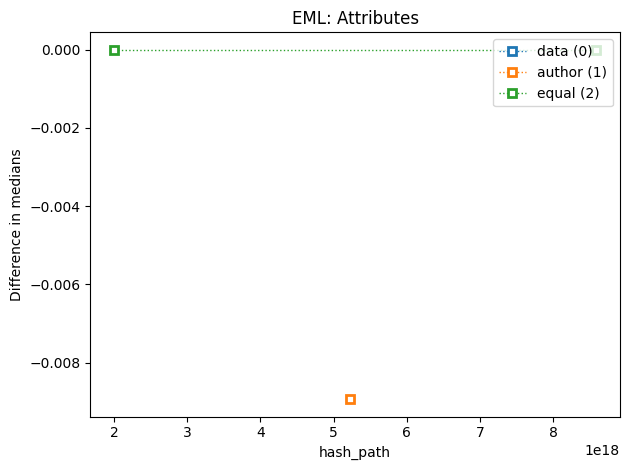


--> top10: data is better:


,ds_med_cont
count,0.0
mean,NaN
std,NaN
min,NaN
25%,NaN
50%,NaN
75%,NaN
max,NaN


,path,case_count,ds_count,ds_std_pop,ds_mean,ds_max,ds_min,ds_med_cont,ds_p25_cont,ds_p75_cont
hash_path,,,,,,,,,,


,path,case_count,ds_count,ds_std_pop,ds_mean,ds_max,ds_min,ds_med_cont,ds_p25_cont,ds_p75_cont
hash_path,,,,,,,,,,



--> top10: author is better:


...

,path,case_count,ds_count,ds_std_pop,ds_mean,ds_max,ds_min,ds_med_cont,ds_p25_cont,ds_p75_cont
hash_path,,,,,,,,,,
5227831486160219788,.,148,148,0.077092,0.534112,0.690815,0.333798,0.56357,0.478284,0.590497



--> top10: equal:


,ds_med_cont
count,2.0
mean,0.0
std,0.0
min,0.0
25%,0.0
50%,0.0
75%,0.0
max,0.0


,path,case_count,ds_count,ds_std_pop,ds_mean,ds_max,ds_min,ds_med_cont,ds_p25_cont,ds_p75_cont
hash_path,,,,,,,,,,
8583186042160731940,dataset/creator/userId,17,17,0.129199,0.952133,0.990047,0.436759,0.990047,0.967233,0.990047
2007448060941507434,dataset/project/studyAreaDescription/descriptor,11,11,0.020384,0.794280,0.800726,0.729819,0.800726,0.800726,0.800726


,path,case_count,ds_count,ds_std_pop,ds_mean,ds_max,ds_min,ds_med_cont,ds_p25_cont,ds_p75_cont
hash_path,,,,,,,,,,
8583186042160731940,dataset/creator/userId,17,17,0.129199,0.952133,0.990047,0.436759,0.990047,0.967233,0.990047
2007448060941507434,dataset/project/studyAreaDescription/descriptor,11,11,0.027349,0.787834,0.800726,0.729819,0.800726,0.800726,0.800726


In [122]:
df1 = cons_gt_eml_data_nodes_cos_sim_attributes__path_inspect
df2 = cons_gt_eml_author_nodes_cos_sim_attributes__path_inspect

# plt.subplots(figsize=(4.2, 2.8), dpi=300)
plt.title("EML: Attributes")
plt.ylabel("Difference in medians")

delta_med = (df1["ds_med_cont"] - df2["ds_med_cont"])
print(f"{delta_med.shape=}")
print(f"{delta_med.count()=}")
print(f"{len(set.intersection(set(df1.index), set(df2.index)))}")


dw = (delta_med[delta_med > 0])
aw = (delta_med[delta_med < 0])
eq = (delta_med[delta_med == 0])
dw.plot(marker="s", markerfacecolor="w", lw=1, ls=":", mew=2, color=mpl.cm.tab10(0), label=f"data ({dw.count()})", legend=True)
aw.plot(marker="s", markerfacecolor="w", lw=1, ls=":", mew=2, color=mpl.cm.tab10(1), label=f"author ({aw.count()})", legend=True)
eq.plot(marker="s", markerfacecolor="w", lw=1, ls=":", mew=2, color=mpl.cm.tab10(2), label=f"equal ({eq.count()})", legend=True)

plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

print("\n--> top10: data is better:")
display(delta_med[delta_med > 0].describe())
data_bs1 = df1.loc[delta_med[delta_med > 0].index]
data_bs2 = df2.loc[delta_med[delta_med > 0].index]
display(data_bs1[data_bs1["case_count"] > 1].nlargest(10, columns=["ds_med_cont"]))
display(data_bs2[data_bs2["case_count"] > 1].nlargest(10, columns=["ds_med_cont"]))

print("\n--> top10: author is better:")
display(delta_med[delta_med < 0].describe())
author_bs1 = df1.loc[delta_med[delta_med < 0].index]
author_bs2 = df2.loc[delta_med[delta_med < 0].index]
display(author_bs1[author_bs1["case_count"] > 1].nlargest(10, columns=["ds_med_cont"]))
display(author_bs2[author_bs2["case_count"] > 1].nlargest(10, columns=["ds_med_cont"]))

print("\n--> top10: equal:")
display(delta_med[delta_med == 0].describe())
equal_bs1 = df1.loc[delta_med[delta_med == 0].index]
equal_bs2 = df2.loc[delta_med[delta_med == 0].index]
display(equal_bs1[equal_bs1["case_count"] > 1].nlargest(10, columns=["ds_med_cont"]))
display(equal_bs2[equal_bs2["case_count"] > 1].nlargest(10, columns=["ds_med_cont"]))

### Exploratory materials

> EML - Text

In [123]:
%%sql
SELECT c.path, c.case_id, c.cons_has_text, c.cons_text, c.gt_has_text, c.gt_text
FROM shared_cons_gt_eml_author_nodes AS c
WHERE (NOT cons_has_text) AND gt_has_text;

Running query in 'duckdb'

,path,case_id,cons_has_text,cons_text,gt_has_text,gt_text
0,dataset/abstract,0,False,\n,True,\n The present work provides an inv...
1,dataset/abstract,21,False,\n,True,\n Specimen data to accompany: Thér...
2,dataset/abstract,4,False,\n,True,\n This dataset contains the first ...


In [124]:
%%sql
SELECT c.path, c.case_id, c.cons_has_text, c.cons_text, c.gt_has_text, c.gt_text
FROM shared_cons_gt_eml_data_nodes AS c
WHERE (cons_has_text) AND (NOT gt_has_text);

Running query in 'duckdb'

,path,case_id,cons_has_text,cons_text,gt_has_text,gt_text
0,dataset/maintenance/description/para,0,True,Dataset status: not-derived-010,False,None
1,additionalMetadata/metadata,0,True,\n not-derived-012\n,False,\n
2,dataset/maintenance/description/para,10,True,Dataset status: not-derived-010,False,None
3,additionalMetadata/metadata,10,True,\n not-derived-012\n,False,\n
4,dataset/maintenance/description/para,100,True,Dataset status: not-derived-010,False,None
...,...,...,...,...,...,...
207,additionalMetadata/metadata,95,True,\n not-derived-012\n,False,\n
208,dataset/maintenance/description/para,126,True,Dataset status: not-derived-010,False,None
209,dataset/methods/methodStep/description/para,126,True,not-derived-004,False,None
210,dataset/maintenance/description/para,128,True,Dataset status: not-derived-010,False,None


In [125]:
%%sql
SELECT c.path, c.case_id, c.cons_has_text, c.cons_text, c.gt_has_text, c.gt_text
FROM shared_cons_gt_eml_author_nodes AS c
WHERE (cons_has_text) AND (NOT gt_has_text);

Running query in 'duckdb'

,path,case_id,cons_has_text,cons_text,gt_has_text,gt_text
0,dataset/maintenance/description/para,0,True,Dataset status: not-derived-010,False,None
1,additionalMetadata/metadata,0,True,"\n identificationRemarks = ""Morphospecie'...",False,\n
2,dataset/maintenance/description/para,10,True,Dataset status: not-derived-010,False,None
3,dataset/project/personnel/role,10,True,Principal Investigator,False,None
4,additionalMetadata/metadata,10,True,\n not-derived-012\n,False,\n
...,...,...,...,...,...,...
214,dataset/maintenance/description/para,128,True,Dataset status: not-derived-010,False,None
215,additionalMetadata/metadata,128,True,\n not-derived-012\n,False,\n
216,dataset/maintenance/description/para,98,True,Dataset status: not-derived-010,False,None
217,additionalMetadata/metadata,98,True,\n No additional narrative metadata beyon...,False,\n


> EML - Atributes

> False Positives

In [126]:
%%sql
SELECT c.path, c.case_id, c.cons_has_attributes, c.cons_attributes, c.gt_has_attributes, c.gt_attributes
FROM shared_cons_gt_eml_author_nodes AS c
WHERE (c.cons_has_attributes) AND (NOT c.gt_has_attributes);

Running query in 'duckdb'

,path,case_id,cons_has_attributes,cons_attributes,gt_has_attributes,gt_attributes
0,dataset,112,True,"{""id"": ""aedes_collection_dataset""}",False,{}
1,additionalMetadata,115,True,"{""id"": ""am-1""}",False,{}
2,additionalMetadata,139,True,"{""id"": ""am1""}",False,{}
3,dataset,144,True,"{""id"": ""dataset-1""}",False,{}
4,additionalMetadata,144,True,"{""id"": ""am-1""}",False,{}
5,additionalMetadata,163,True,"{""id"": ""am-001""}",False,{}
6,additionalMetadata,169,True,"{""id"": ""addl-1""}",False,{}
7,additionalMetadata,34,True,"{""id"": ""am-1""}",False,{}
8,additionalMetadata,39,True,"{""id"": ""am-1""}",False,{}
9,additionalMetadata,50,True,"{""id"": ""am-1""}",False,{}


In [127]:
%%sql
SELECT DISTINCT c.path
FROM shared_cons_gt_eml_author_nodes AS c
WHERE (c.cons_has_attributes) AND (NOT c.gt_has_attributes);

Running query in 'duckdb'

,path
0,dataset
1,additionalMetadata


In [128]:
%%sql
SELECT c.path, c.case_id, c.cons_has_attributes, c.cons_attributes, c.gt_has_attributes, c.gt_attributes
FROM shared_cons_gt_eml_data_nodes AS c
WHERE (c.cons_has_attributes) AND (NOT c.gt_has_attributes);

Running query in 'duckdb'

,path,case_id,cons_has_attributes,cons_attributes,gt_has_attributes,gt_attributes
0,additionalMetadata,100,True,"{""id"": ""am-1""}",False,{}
1,additionalMetadata,125,True,"{""id"": ""am-1""}",False,{}
2,additionalMetadata,137,True,"{""id"": ""ext-1""}",False,{}
3,additionalMetadata,151,True,"{""id"": ""am-1""}",False,{}
4,dataset,169,True,"{""id"": ""203-37e24322-a8b9-3f3f-8686-4fa43445dc...",False,{}
5,additionalMetadata,18,True,"{""id"": ""am-1""}",False,{}
6,additionalMetadata,21,True,"{""id"": ""customExtensions""}",False,{}
7,additionalMetadata,29,True,"{""id"": ""am1""}",False,{}
8,additionalMetadata,3,True,"{""id"": ""am-1""}",False,{}
9,additionalMetadata,39,True,"{""id"": ""am1""}",False,{}


In [129]:
%%sql
SELECT DISTINCT c.path
FROM shared_cons_gt_eml_author_nodes AS c
WHERE (c.cons_has_attributes) AND (NOT c.gt_has_attributes);

Running query in 'duckdb'

,path
0,dataset
1,additionalMetadata


> False Negatives

In [130]:
%%sql
SELECT c.path, c.case_id, c.cons_has_attributes, c.cons_attributes, c.gt_has_attributes, c.gt_attributes
FROM shared_cons_gt_eml_author_nodes AS c
WHERE (NOT c.cons_has_attributes) AND (c.gt_has_attributes);

Running query in 'duckdb'

,path,case_id,cons_has_attributes,cons_attributes,gt_has_attributes,gt_attributes
0,dataset/title,0,False,{},True,"{""{http://www.w3.org/XML/1998/namespace}lang"":..."
1,dataset/project,0,False,{},True,"{""id"": ""COASTAL ECOSYSTEMS""}"
2,dataset/title,10,False,{},True,"{""{http://www.w3.org/XML/1998/namespace}lang"":..."
3,dataset/project,10,False,{},True,"{""id"": ""IDIT""}"
4,dataset/title,100,False,{},True,"{""{http://www.w3.org/XML/1998/namespace}lang"":..."
...,...,...,...,...,...,...
192,dataset/title,128,False,{},True,"{""{http://www.w3.org/XML/1998/namespace}lang"":..."
193,dataset/title,129,False,{},True,"{""{http://www.w3.org/XML/1998/namespace}lang"":..."
194,dataset/project,98,False,{},True,"{""id"": ""LIFEWATCH-2019-09-CSIC-4, POPE 2014-20..."
195,dataset/title,99,False,{},True,"{""{http://www.w3.org/XML/1998/namespace}lang"":..."


In [131]:
%%sql
SELECT DISTINCT c.path
FROM shared_cons_gt_eml_author_nodes AS c
WHERE (NOT c.cons_has_attributes) AND (c.gt_has_attributes);

Running query in 'duckdb'

,path
0,dataset/title
1,dataset/project


In [132]:
%%sql
SELECT DISTINCT gt_attributes
FROM shared_cons_gt_eml_author_nodes AS c
WHERE (NOT c.cons_has_attributes) AND (c.gt_has_attributes);

Running query in 'duckdb'

,gt_attributes
0,"{""{http://www.w3.org/XML/1998/namespace}lang"":..."
1,"{""id"": ""2022.01/0013""}"
2,"{""id"": ""https://doi.org/10.32800/amz.2023.21.0..."
3,"{""{http://www.w3.org/XML/1998/namespace}lang"":..."
4,"{""id"": ""N-Eurasia-2022""}"
5,"{""id"": ""Arthropods_Azorean_Urban_Gardens""}"
6,"{""id"": ""DB-F-44""}"
7,"{""id"": ""mosquitoalert""}"
8,"{""id"": ""210484467217""}"
9,"{""id"": ""DARCO-AZORES""}"


In [133]:
%%sql
SELECT c.path, c.case_id, c.cons_has_attributes, c.cons_attributes, c.gt_has_attributes, c.gt_attributes
FROM shared_cons_gt_eml_data_nodes AS c
WHERE (NOT c.cons_has_attributes) AND (c.gt_has_attributes);

Running query in 'duckdb'

,path,case_id,cons_has_attributes,cons_attributes,gt_has_attributes,gt_attributes
0,dataset/title,0,False,{},True,"{""{http://www.w3.org/XML/1998/namespace}lang"":..."
1,dataset/project,0,False,{},True,"{""id"": ""COASTAL ECOSYSTEMS""}"
2,dataset/title,10,False,{},True,"{""{http://www.w3.org/XML/1998/namespace}lang"":..."
3,dataset/project,10,False,{},True,"{""id"": ""IDIT""}"
4,dataset/title,100,False,{},True,"{""{http://www.w3.org/XML/1998/namespace}lang"":..."
...,...,...,...,...,...,...
193,dataset/title,95,False,{},True,"{""{http://www.w3.org/XML/1998/namespace}lang"":..."
194,dataset/title,97,False,{},True,"{""{http://www.w3.org/XML/1998/namespace}lang"":..."
195,dataset/title,98,False,{},True,"{""{http://www.w3.org/XML/1998/namespace}lang"":..."
196,dataset/title,128,False,{},True,"{""{http://www.w3.org/XML/1998/namespace}lang"":..."


In [134]:
%%sql
SELECT DISTINCT c.path
FROM shared_cons_gt_eml_data_nodes AS c
WHERE (NOT c.cons_has_attributes) AND (c.gt_has_attributes);

Running query in 'duckdb'

,path
0,dataset/title
1,dataset/project
2,dataset/distribution
3,dataset/distribution/online/url


In [135]:
%%sql
SELECT DISTINCT gt_attributes
FROM shared_cons_gt_eml_data_nodes AS c
WHERE (NOT c.cons_has_attributes) AND (c.gt_has_attributes);

Running query in 'duckdb'

,gt_attributes
0,"{""{http://www.w3.org/XML/1998/namespace}lang"":..."
1,"{""id"": ""https://doi.org/10.32800/amz.2023.21.0..."
2,"{""id"": ""210484467217""}"
3,"{""id"": ""PICT 01-11749""}"
4,"{""id"": ""BID-AF2015-0042-NAC""}"
5,"{""id"": ""42271116""}"
6,"{""scope"": ""document""}"
7,"{""id"": ""Arthropods_Azorean_Urban_Gardens""}"
8,"{""id"": ""N-Eurasia-2022""}"
9,"{""id"": ""DB-F-44""}"


> DwC-T

In [136]:
%%sql
SELECT c.path, c.tag, c.case_id, c.cons_has_attributes, c.cons_attributes, c.gt_has_attributes, c.gt_attributes
FROM shared_cons_gt_dwc_t_author_nodes AS c
WHERE (cons_has_attributes) AND (NOT gt_has_attributes);

Running query in 'duckdb'

,path,tag,case_id,cons_has_attributes,cons_attributes,gt_has_attributes,gt_attributes
0,.,{http://rs.tdwg.org/dwc/text/}archive,111,True,"{""metadata"": ""not-derived-001""}",False,{}
1,.,{http://rs.tdwg.org/dwc/text/}archive,124,True,"{""metadata"": ""not-derived-001""}",False,{}
2,.,{http://rs.tdwg.org/dwc/text/}archive,52,True,"{""metadata"": ""not-derived-001""}",False,{}


In [137]:
%%sql
SELECT c.path, c.tag, c.case_id, c.cons_has_attributes, c.cons_attributes, c.gt_has_attributes, c.gt_attributes
FROM shared_cons_gt_dwc_t_data_nodes AS c
WHERE (cons_has_attributes) AND (NOT gt_has_attributes);

Running query in 'duckdb'

,path,tag,case_id,cons_has_attributes,cons_attributes,gt_has_attributes,gt_attributes
0,.,{http://rs.tdwg.org/dwc/text/}archive,111,True,"{""metadata"": ""meta.xml""}",False,{}
1,.,{http://rs.tdwg.org/dwc/text/}archive,124,True,"{""metadata"": ""meta.xml""}",False,{}
2,.,{http://rs.tdwg.org/dwc/text/}archive,52,True,"{""metadata"": ""meta.xml""}",False,{}


In [138]:
%%sql
SELECT c.path, c.cons_attributes, c.gt_attributes, COUNT(1)
FROM shared_cons_gt_dwc_t_data_nodes AS c
WHERE c.path = '.'
GROUP BY 1,2,3;

Running query in 'duckdb'

,path,cons_attributes,gt_attributes,count(1)
0,.,"{""metadata"": ""meta.xml""}","{""metadata"": ""eml.xml""}",109
1,.,"{""metadata"": ""not-derived-001""}","{""metadata"": ""eml.xml""}",59
2,.,"{""metadata"": ""GAP_001""}","{""metadata"": ""eml.xml""}",1
3,.,"{""metadata"": ""1""}","{""metadata"": ""eml.xml""}",1
4,.,"{""metadata"": ""Ascorhynchus hippos Turpaeva, 19...","{""metadata"": ""eml.xml""}",1
5,.,"{""metadata"": ""meta.xml""}",{},3


In [139]:
%%sql
SELECT c.path, c.cons_attributes, c.gt_attributes, AVG(cos_sim_attributes), COUNT(1)
FROM cons_gt_dwc_t_author_nodes_cos_sim_attributes AS c
WHERE c.path = '.'
GROUP BY 1,2,3;

Running query in 'duckdb'

,path,cons_attributes,gt_attributes,avg(cos_sim_attributes),count(1)
0,.,"{""metadata"": ""meta.xml""}","{""metadata"": ""eml.xml""}",0.771236,30
1,.,"{""metadata"": ""not-derived-001""}","{""metadata"": ""eml.xml""}",0.551474,134
2,.,"{""metadata"": ""omit the metadata attribute""}","{""metadata"": ""eml.xml""}",0.635459,2
3,.,"{""metadata"": ""https://doi.org/10.15468/gwr8mg""}","{""metadata"": ""eml.xml""}",0.557783,1
4,.,"{""metadata"": ""https://www.gbif.org/dataset/e9a...","{""metadata"": ""eml.xml""}",0.533566,1
5,.,"{""metadata"": ""not-derived-001` is unavailable....","{""metadata"": ""eml.xml""}",0.554140,1
6,.,"{""metadata"": ""omit the `metadata` attribute""}","{""metadata"": ""eml.xml""}",0.635781,1
7,.,"{""metadata"": ""omit or leave empty""}","{""metadata"": ""eml.xml""}",0.531999,1


In [140]:
compute_cos_similarity("not-derived-001", "eml.xml")

-0.015909384936094284

In [141]:
%%sql
SELECT c.path, c.cons_attributes, c.gt_attributes, AVG(cos_sim_attributes), COUNT(1)
FROM cons_gt_dwc_t_data_nodes_cos_sim_attributes AS c
WHERE c.path = '.'
GROUP BY 1,2,3;

Running query in 'duckdb'

,path,cons_attributes,gt_attributes,avg(cos_sim_attributes),count(1)
0,.,"{""metadata"": ""meta.xml""}","{""metadata"": ""eml.xml""}",0.771236,109
1,.,"{""metadata"": ""not-derived-001""}","{""metadata"": ""eml.xml""}",0.551474,59
2,.,"{""metadata"": ""GAP_001""}","{""metadata"": ""eml.xml""}",0.542274,1
3,.,"{""metadata"": ""1""}","{""metadata"": ""eml.xml""}",0.677672,1
4,.,"{""metadata"": ""Ascorhynchus hippos Turpaeva, 19...","{""metadata"": ""eml.xml""}",0.424147,1


In [142]:
%%sql
WITH distinct_root_gt_attributes AS (
  SELECT DISTINCT (c.gt_attributes :: JSON) AS gt_attributes_json
  FROM cons_gt_dwc_t_data_nodes_cos_sim_attributes AS c
  WHERE c.path = '.'
)
SELECT *
FROM distinct_root_gt_attributes as attr, json_each(attr.gt_attributes_json)

Running query in 'duckdb'

,gt_attributes_json,key,value,type,atom,id,parent,fullkey,path
0,"{""metadata"": ""eml.xml""}",metadata,"""eml.xml""",VARCHAR,"""eml.xml""",2,<NA>,$.metadata,$


In [143]:
%%sql
WITH distinct_root_gt_attributes AS (
  SELECT DISTINCT (c.gt_attributes :: JSON) AS gt_attributes_json
  FROM cons_gt_dwc_t_data_nodes_cos_sim_attributes AS c
)
SELECT DISTINCT key
FROM distinct_root_gt_attributes as attr, json_each(attr.gt_attributes_json)

Running query in 'duckdb'

,key
0,rowType
1,index
2,term
3,fieldsEnclosedBy
4,encoding
5,metadata
6,ignoreHeaderLines
7,delimitedBy
8,linesTerminatedBy
9,fieldsTerminatedBy


In [207]:
%%sql cons_gt_eml_author_nodes_cos_sim_text__dataset_title <<
SELECT c.path,
    c.case_id,
    cons_text, gt_text,
    cos_sim_text
FROM cons_gt_eml_author_nodes_cos_sim_text AS c
WHERE c.path = 'dataset/title'
ORDER BY cos_sim_text DESC;



Running query in 'duckdb'

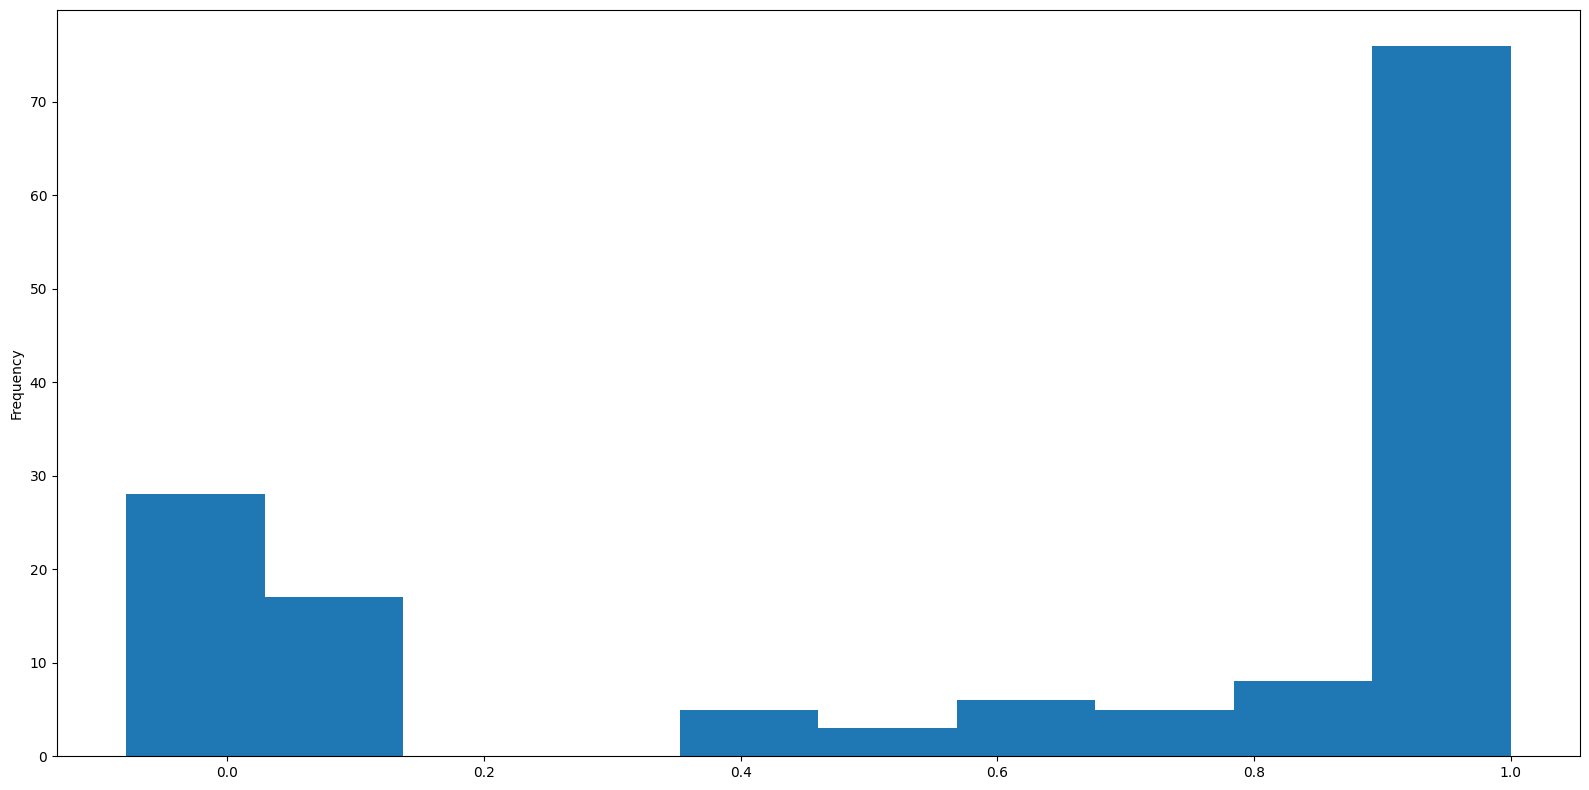

In [205]:
fig, ax = plt.subplots(figsize=(16,8))
cons_gt_eml_author_nodes_cos_sim_text__dataset_title["cos_sim_text"].plot.hist(ax=ax)
plt.tight_layout()

In [220]:
%%sql
SELECT c.path, ds_mean, ds_med_cont, ds_count
FROM cons_gt_eml_data_nodes_cos_sim_text__path_inspect AS c
ORDER BY ds_med_cont DESC;

Running query in 'duckdb'

,path,ds_mean,ds_med_cont,ds_count
0,dataset/coverage/temporalCoverage/rangeOfDates...,1.000000,1.000000,1
1,dataset/coverage/temporalCoverage/rangeOfDates...,1.000000,1.000000,1
2,dataset/contact/individualName/givenName,1.000000,1.000000,1
3,dataset/contact/individualName/surName,1.000000,1.000000,1
4,dataset/coverage/geographicCoverage/geographic...,0.665401,0.665401,1
5,dataset/abstract/para,0.426243,0.518044,11
6,dataset/project/personnel[7]/individualName/su...,0.472188,0.472188,1
7,dataset/intellectualRights/para,0.448450,0.448450,1
8,dataset/methods/methodStep[1]/description/para,0.433869,0.444099,4
9,dataset/methods/sampling/studyExtent/descripti...,0.407178,0.426475,3


In [221]:
%%sql
SELECT c.path, ds_mean, ds_med_cont, ds_count
FROM cons_gt_eml_author_nodes_cos_sim_text__path_inspect AS c
ORDER BY ds_med_cont DESC;


Running query in 'duckdb'

,path,ds_mean,ds_med_cont,ds_count
0,dataset/project/personnel[1]/individualName/gi...,1.000000,1.000000,1
1,dataset/title,0.627410,0.898597,148
2,dataset/project/personnel[2]/individualName/gi...,0.813631,0.813631,1
3,dataset/coverage/geographicCoverage/geographic...,0.569407,0.569407,2
4,dataset/abstract/para,0.414720,0.520462,7
5,dataset/methods/methodStep[1]/description/para,0.315588,0.458055,7
6,dataset/methods/methodStep[2]/description/para,0.356656,0.416618,8
7,dataset/intellectualRights/para,0.412951,0.412951,1
8,dataset/maintenance/description/para,0.381276,0.398156,8
9,dataset/project/personnel[1]/role,0.324028,0.344871,19


In [166]:
%%sql
SELECT c.path, c.cons_attributes, c.gt_attributes, AVG(cos_sim_attributes), COUNT(1)
FROM cons_gt_eml_data_nodes_cos_sim_attributes AS c
WHERE c.path = '.'
GROUP BY 1,2,3;

Running query in 'duckdb'

,path,cons_attributes,gt_attributes,avg(cos_sim_attributes),count(1)
0,.,"{""packageId"": ""not-derived-013"", ""system"": ""knb""}","{""{http://www.w3.org/2001/XMLSchema-instance}s...",0.422771,1
1,.,"{""packageId"": ""uuid:5afad484-90d6-47c1-bc7f-3c...","{""{http://www.w3.org/2001/XMLSchema-instance}s...",0.548553,1
2,.,"{""packageId"": ""not-derived-013"", ""system"": ""kn...","{""{http://www.w3.org/2001/XMLSchema-instance}s...",0.575319,1
3,.,"{""packageId"": ""not-derived-000"", ""system"": ""knb""}","{""{http://www.w3.org/2001/XMLSchema-instance}s...",0.440611,1
4,.,"{""packageId"": ""doi:10.15470/vqshir"", ""system"":...","{""{http://www.w3.org/2001/XMLSchema-instance}s...",0.466688,1
...,...,...,...,...,...
145,.,"{""packageId"": ""not-derived-000"", ""system"": ""knb""}","{""{http://www.w3.org/2001/XMLSchema-instance}s...",0.433899,1
146,.,"{""packageId"": ""10.1007/978-1-0716-2313-8_8"", ""...","{""{http://www.w3.org/2001/XMLSchema-instance}s...",0.633892,1
147,.,"{""packageId"": ""urn:uuid:1f0d2b5a-7c4d-4b1d-9d8...","{""{http://www.w3.org/2001/XMLSchema-instance}s...",0.422569,1
148,.,"{""packageId"": ""urn:uuid:3f8f6f6a-8f2b-4d1b-9d8...","{""{http://www.w3.org/2001/XMLSchema-instance}s...",0.570938,1


In [170]:
%%sql
SELECT c.path, c.cons_attributes, c.gt_attributes, AVG(cos_sim_attributes), COUNT(1)
FROM cons_gt_eml_author_nodes_cos_sim_attributes AS c
WHERE c.path = 'dataset/creator/userId'
GROUP BY 1,2,3;

Running query in 'duckdb'

,path,cons_attributes,gt_attributes,avg(cos_sim_attributes),count(1)
0,dataset/creator/userId,"{""directory"": ""https://orcid.org""}","{""directory"": ""https://orcid.org/""}",0.990047,12
1,dataset/creator/userId,"{""directory"": ""https://orcid.org""}","{""directory"": ""http://scholar.google.com/citat...",0.436759,1
2,dataset/creator/userId,"{""directory"": ""https://orcid.org""}","{""directory"": ""http://orcid.org/""}",0.967233,4


In [173]:
%%sql
SELECT c.path, c.cons_attributes, c.gt_attributes, AVG(cos_sim_attributes), COUNT(1)
FROM cons_gt_eml_data_nodes_cos_sim_attributes AS c
WHERE c.path IN ('dataset/creator/userId','dataset/creator[1]/userId','dataset/creator[2]/userId')
GROUP BY 1,2,3;

Running query in 'duckdb'

,path,cons_attributes,gt_attributes,avg(cos_sim_attributes),count(1)
0,dataset/creator/userId,"{""directory"": ""https://orcid.org""}","{""directory"": ""https://orcid.org/""}",0.990047,12
1,dataset/creator/userId,"{""directory"": ""https://orcid.org""}","{""directory"": ""http://scholar.google.com/citat...",0.436759,1
2,dataset/creator/userId,"{""directory"": ""https://orcid.org""}","{""directory"": ""http://orcid.org/""}",0.967233,4
3,dataset/creator[1]/userId,"{""directory"": ""https://orcid.org""}","{""directory"": ""https://orcid.org/""}",0.990047,1
4,dataset/creator[2]/userId,"{""directory"": ""https://orcid.org""}","{""directory"": ""https://orcid.org/""}",0.990047,1


In [174]:
%%sql
SELECT c.path, c.cons_attributes, c.gt_attributes, AVG(cos_sim_attributes), COUNT(1)
FROM cons_gt_eml_author_nodes_cos_sim_attributes AS c
WHERE c.path = 'dataset/project/studyAreaDescription/descriptor'
GROUP BY 1,2,3;

Running query in 'duckdb'

,path,cons_attributes,gt_attributes,avg(cos_sim_attributes),count(1)
0,dataset/project/studyAreaDescription/descriptor,"{""name"": ""habitat_type"", ""citableClassificatio...","{""name"": ""generic"", ""citableClassificationSyst...",0.800726,9
1,dataset/project/studyAreaDescription/descriptor,"{""name"": ""study_area"", ""citableClassificationS...","{""name"": ""generic"", ""citableClassificationSyst...",0.729819,2


In [175]:
%%sql
SELECT c.path, c.cons_attributes, c.gt_attributes, AVG(cos_sim_attributes), COUNT(1)
FROM cons_gt_eml_data_nodes_cos_sim_attributes AS c
WHERE c.path = 'dataset/project/studyAreaDescription/descriptor'
GROUP BY 1,2,3;

Running query in 'duckdb'

,path,cons_attributes,gt_attributes,avg(cos_sim_attributes),count(1)
0,dataset/project/studyAreaDescription/descriptor,"{""name"": ""habitat_type"", ""citableClassificatio...","{""name"": ""generic"", ""citableClassificationSyst...",0.800726,10
1,dataset/project/studyAreaDescription/descriptor,"{""name"": ""study_area"", ""citableClassificationS...","{""name"": ""generic"", ""citableClassificationSyst...",0.729819,1
